In [43]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [44]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [45]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

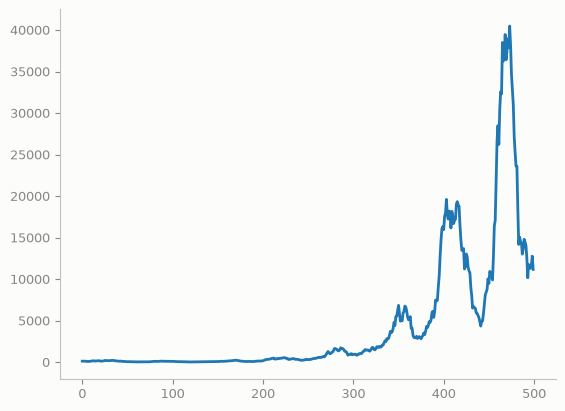

In [46]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [47]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

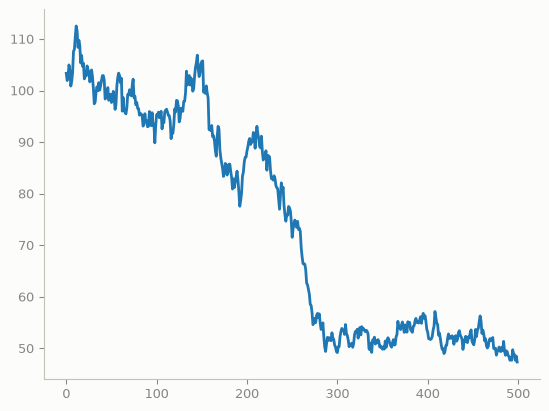

In [48]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [49]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

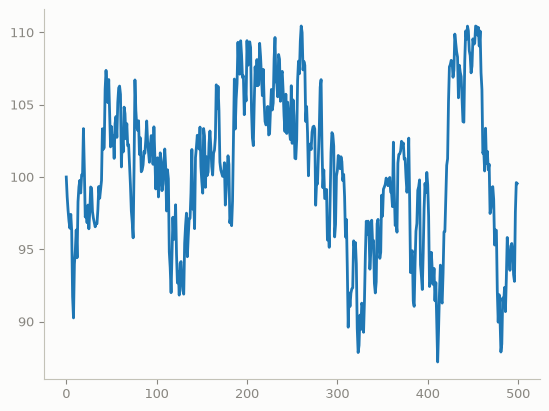

In [50]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [51]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

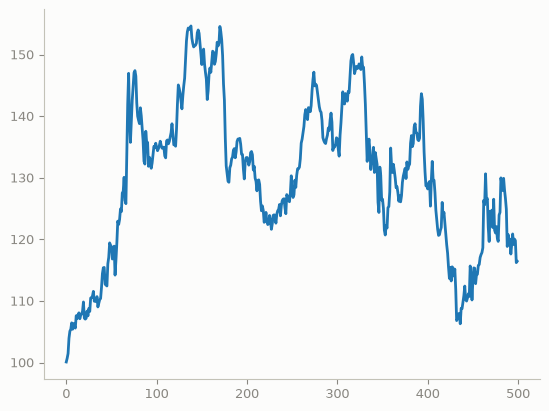

In [52]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [53]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [54]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

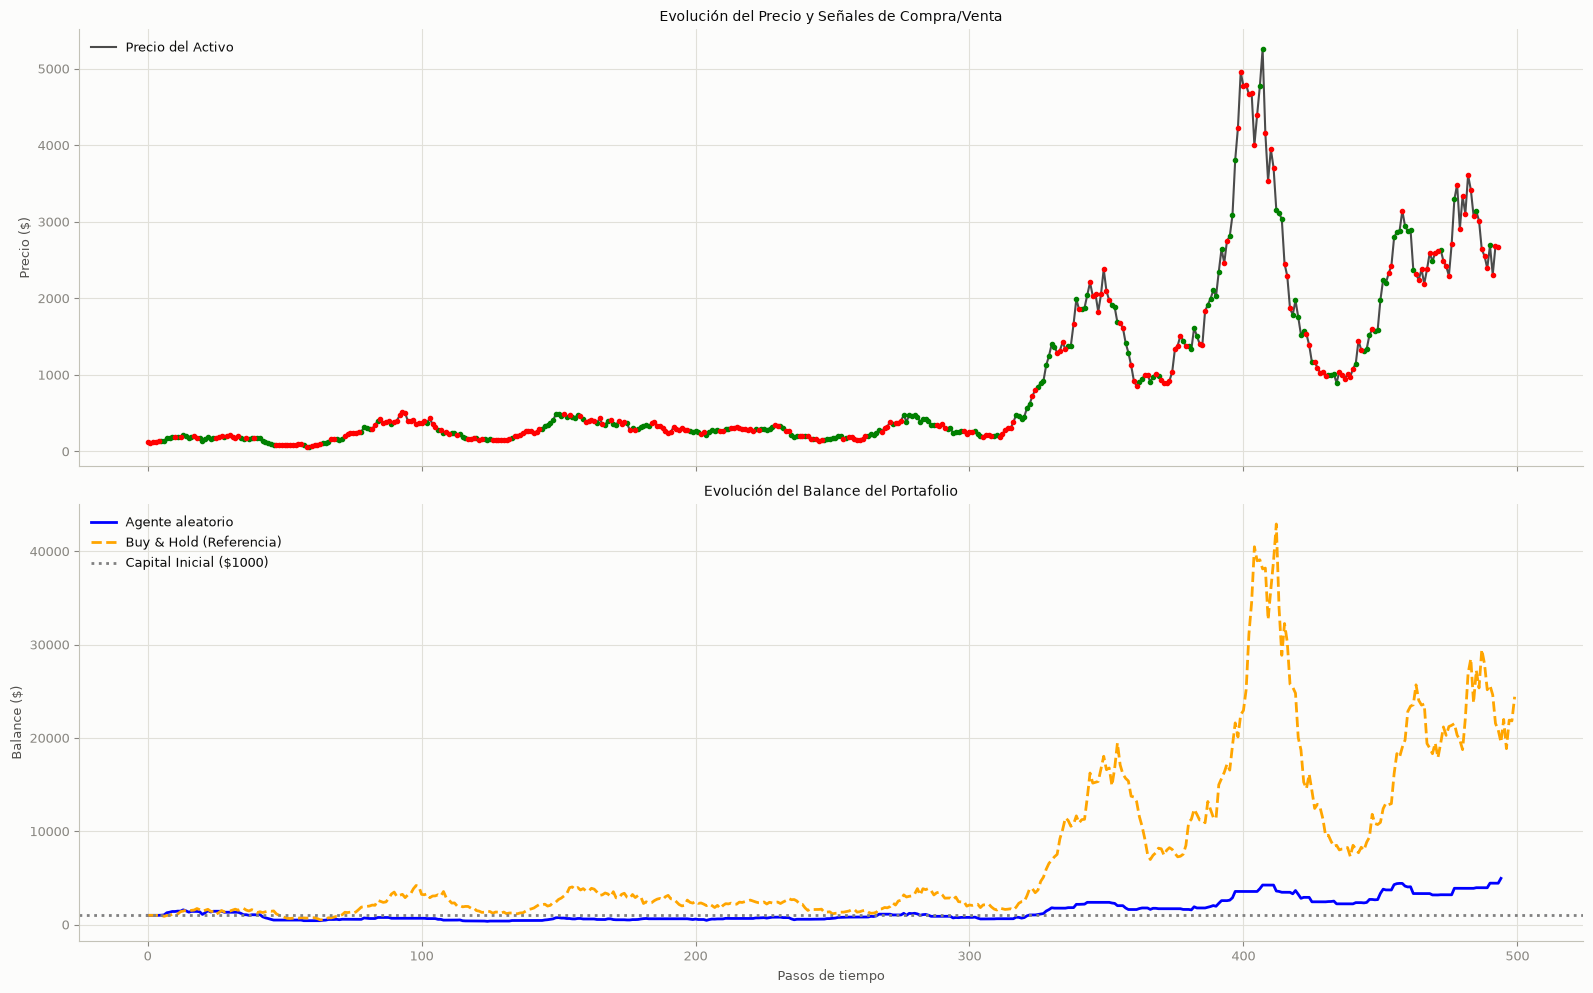

In [55]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *DQN* y *A3C*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **5/11/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a manuel.smontanes@gmail.com antes de la clase del jueves 5 de noviembre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 3 de noviembre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

---

# Resolución de los ejercicios

Esta parte resuelve los cuatro ejercicios: entrena **DQN** y **A3C** (más **Doble DQN**, **DQN en duelo** y **REINFORCE**, también vistos en clase) en los cuatro mercados, ajusta sus hiperparámetros y los compara con las referencias.

**Cómo usar este notebook**

- *Ejecutar todo* funciona siempre. Cada cálculo guarda sus resultados en `results/` según termina y **no repite lo que ya está hecho**.
- **Se puede suspender el ordenador o cerrar el notebook:** al volver a ejecutar, continúa donde se quedó. Como mucho se repiten los entrenamientos que estaban a medias.
- Con `EJECUTAR_CALCULOS = False` no se entrena nada: solo se muestra lo que ya hay en `results/`. Es lo cómodo para repasar resultados.
- Para empezar de cero hay que borrar la carpeta `results/` (salvo `referencia_tabular_fase3.csv`). Todo el cálculo tarda unas 4,5 horas con 16 núcleos, con el portátil enchufado.

**Dónde está el código.** Los algoritmos están en `rl_trader/` y aquí se muestran con `mostrar(...)`. No pueden definirse dentro del notebook: en Windows, cada proceso en paralelo (imprescindible en A3C) tiene que importar sus funciones desde un archivo `.py`.

In [56]:
# True: entrena lo que falte (horas). False: solo muestra lo que ya está en results/
EJECUTAR_CALCULOS = True

import inspect
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))

from rl_trader import analisis, graficas
from rl_trader.a3c import Trabajador, entrenar_a3c
from rl_trader.agentes import Agente, AgenteActorCritico
from rl_trader.analisis import MERCADOS, NOMBRES_AGENTE, NOMBRES_MERCADO, RESULTADOS
from rl_trader.dqn import AgenteDQN, entrenar_dqn
from rl_trader.evaluation import SEMILLA_TEST, SEMILLA_VALIDACION, generar_series, tendencias
from rl_trader.oraculos import tabla_oraculos
from rl_trader.prices import GENERADORES
from rl_trader.redes import Normalizador, RedActorCritico, RedDuelo, RedQ
from scripts import ajuste, comparar_lotes, convergencia_a3c, datos_reales, resultados

graficas.aplicar_estilo()
pd.set_option("display.max_columns", None, "display.width", 200)


def mostrar(objeto):
    '''Muestra el código fuente de una clase o función, tal como está en rl_trader/.'''
    display(Markdown(f"```python\n{inspect.getsource(objeto)}\n```"))


def hay(*archivos):
    '''Indica si ya están los resultados; si no, avisa de que falta ese cálculo.'''
    faltan = [a for a in archivos if not (RESULTADOS / a).exists()]
    if faltan:
        print("Aún no hay resultados para esta celda. Falta:", ", ".join(faltan))
    return not faltan

## 1. Decisiones de diseño

**Estado continuo, sin enventanar.** En el taller anterior la tendencia se repartía en intervalos para indexar una tabla Q. Aquí la red recibe la tendencia continua directamente, y generaliza entre valores parecidos: es la motivación de DQN en las transparencias (*"aproximar, generalizar, explotar la continuidad"*). El estado sigue siendo `(tendencia, posición)` y el entorno no se modifica; la tendencia se sigue calculando con las 6 últimas observaciones porque así la define el enunciado.

| Decisión | Motivo |
|---|---|
| **Normalizar la tendencia** dividiendo por su desviación típica | Vale ±0,3 en ciclo y ±0,05 en el resto: sin esto, la red apenas la vería. Sustituye al ajuste de cortes por cuantiles del `Discretizador` anterior |
| **Normalizar la recompensa** en vez de recortarla a ±1 | Las transparencias avisan de los refuerzos muy diferentes y proponen recortarlos, pero aquí eso borraría la diferencia entre un retorno pequeño y uno grande. Multiplicar por una constante positiva no cambia la política óptima |
| **MSE y MAE** como pérdida | MSE es la de las transparencias: Q estima la **media** del target. Con MAE estima su **mediana** y el error grande pesa menos. Se comparan en la etapa C |
| **Actor y crítico separados**, con α<sub>θ</sub> y α<sub>w</sub> | Como en las transparencias. Además, el error del crítico, muy ruidoso, taparía la señal del actor si compartieran capas |
| **Sin el factor I = γ<sup>t</sup>** de las transparencias | Optimiza solo el valor del estado inicial, que aquí no tiene nada de especial. Con γ = 0,9 anularía el aprendizaje del actor a los pocos pasos de cada serie. Tampoco lo usa el artículo de A3C |
| **Entropía β** como exploración en A3C | Es el equivalente de ε: A3C ya explora al muestrear de π, y β evita que π se vuelva determinista antes de tiempo |
| **Pesos del mejor control en validación** | Las redes oscilan durante el entrenamiento: el último control no tiene por qué ser el mejor |
| **Un hilo por entrenamiento, sin GPU** | Con redes de 64×64 y entradas de 2 valores, más hilos o la GPU van más lentos |
| **Cerrojo corto en el paso de Adam de A3C** | Sin él hay una carrera real que dispara los pesos (sección 9). Los gradientes se siguen calculando de forma asíncrona, sobre pesos que otros trabajadores están cambiando |

**Datos.** Cada episodio usa una serie nueva. Validación y test (100 series cada uno) salen de semillas separadas y son comunes a todos los agentes. Son las **mismas series de test del taller anterior**, así que se pueden comparar los resultados. La métrica principal es la mediana del retorno, porque en el mercado de ciclo unas pocas series disparan la media.

### Antes de entrenar: ¿qué estrategia esperamos?

Para poder razonar luego si cada agente hace lo esperado, medimos antes de entrenar qué retorno sigue, en media, a cada valor de la tendencia. Esta figura usa intervalos solo para poder dibujarla: los agentes no los ven.

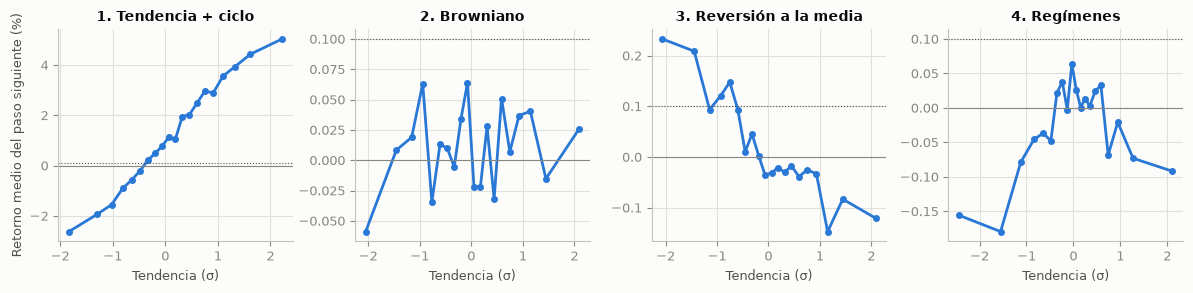

In [57]:
import matplotlib.pyplot as plt
import numpy as np

fig, ejes = plt.subplots(1, 4, figsize=(12, 3))
for ax, mercado in zip(ejes, MERCADOS):
    p = np.array(generar_series(GENERADORES[mercado], 200, 3_900_000_000))
    t = tendencias(p)[:, :-1].ravel()
    r = (p[:, 6:] / p[:, 5:-1] - 1).ravel()
    z = t / t.std()
    bordes = np.quantile(z, np.linspace(0, 1, 21))
    grupos = np.clip(np.digitize(z, bordes[1:-1]), 0, 19)
    medias = np.array([r[grupos == k].mean() for k in range(20)])
    centros = np.array([z[grupos == k].mean() for k in range(20)])
    ax.plot(centros, 100 * medias, "o-", color=graficas.COLORES["dqn"], markersize=4)
    ax.axhline(0, color=graficas.GRIS, linewidth=0.8)
    ax.axhline(0.1, color=graficas.TINTA_2, linewidth=0.8, linestyle=":")
    ax.set_title(NOMBRES_MERCADO[mercado], fontweight="bold")
    ax.set_xlabel("Tendencia (σ)")
ejes[0].set_ylabel("Retorno medio del paso siguiente (%)")
fig.tight_layout()
plt.show()

La línea de puntos marca la comisión del 0,1%. Lo que se puede esperar de un agente racional en cada mercado:

- **Ciclo:** retorno creciente con la tendencia, con mucha inercia. Se espera *momentum*.
- **Browniano:** plano. No hay señal, así que lo sensato es no operar o comprar y mantener.
- **Reversión:** retorno decreciente con la tendencia. Se espera *contrarian*, y solo en los extremos, donde supera la comisión.
- **Regímenes:** señal muy débil. Se espera poco margen sobre no operar.

## 2. Los algoritmos (ejercicio 1)

Todos los agentes guardan su red en `self.modelo` y la llaman directamente. No hay ningún `predict`: al evaluar, la red recibe **la serie entera de una vez**, sin partirla por lotes.

### Agente base

In [58]:
mostrar(Agente)
mostrar(AgenteActorCritico)

```python
class Agente:
    """Agente basado en valor: self.modelo(x) devuelve Q(s, a), y se elige la acción de mayor valor."""

    def __init__(self, modelo, normalizador):
        self.modelo = modelo
        self.normalizador = normalizador

    def preferencias(self, x):
        """Devuelve la salida de la red que ordena las acciones."""
        return self.modelo(x)

    @torch.inference_mode()
    def tablas(self, precios):
        """Evalúa la red en todos los pasos de todas las series: array (series, 2, pasos, 3)."""
        t = tendencias(precios)[:, :-1]
        salida = [self.preferencias(torch.from_numpy(self.normalizador.entrada(t, np.full_like(t, p)))).numpy()
                  for p in (0, 1)]
        return np.stack(salida, axis=1)

    def acciones_greedy(self, precios):
        """Tablas de acciones de la política greedy, listas para evaluation.simular_lote."""
        return self.tablas(precios).argmax(axis=-1)

    @torch.inference_mode()
    def __call__(self, obs):
        """Decide la acción greedy para una observación del entorno."""
        return int(self.preferencias(self.normalizador.obs(obs)).argmax())

    @torch.inference_mode()
    def mapa_politica(self, z=np.linspace(-4, 4, 81)):
        """Evalúa la política continua en una rejilla de tendencias (en desviaciones típicas).

        Devuelve las preferencias de cada acción, (2, len(z), 3). No hay intervalos: la
        frontera de decisión es una curva.
        """
        t = np.asarray(z, dtype=np.float32) * self.normalizador.escala_tendencia
        return np.stack([self.preferencias(torch.from_numpy(self.normalizador.entrada(t, np.full_like(t, p)))).numpy()
                         for p in (0, 1)])

```

```python
class AgenteActorCritico(Agente):
    """Agente basado en política: self.modelo(x) devuelve (logits del actor, valor del crítico)."""

    def preferencias(self, x):
        return self.modelo(x)[0]

    def acciones_muestreadas(self, precios, seed=0):
        """Tablas de acciones muestreadas de la política estocástica del actor."""
        logits = self.tablas(precios)
        # Muestreo de una categórica con el truco de Gumbel: argmax(logits + ruido)
        ruido = np.random.default_rng(seed).gumbel(size=logits.shape)
        return (logits + ruido).argmax(axis=-1)

```

### DQN, Doble DQN y DQN en duelo

Es el algoritmo de las transparencias 1 y 5:

1. La tabla Q se sustituye por una red con una salida lineal por acción.
2. Cada experiencia `(s, a, r, s', terminal)` se guarda en un buffer limitado.
3. Cada 4 pasos se entrena con un **minibatch al azar** del buffer, lo que rompe la correlación entre experiencias seguidas.
4. Cada 1.000 pasos se copia Q en la red objetivo Q', para que el target no se mueva con cada actualización.

La diferencia entre variantes es pequeña:

- **Doble DQN** usa Q para elegir la acción del target y Q' para valorarla, lo que reduce la sobreestimación del `max`.
- **DQN en duelo** separa la salida: $Q(s,a) = V(s) + A(s,a) - \text{media}_{a'}A(s,a')$.

In [59]:
mostrar(AgenteDQN)
mostrar(RedDuelo)

```python
class AgenteDQN(Agente):
    """El agente que aprende: la red Q en self.modelo y la red objetivo Q' en self.modelo_objetivo."""

    def __init__(self, normalizador, ocultas, alpha, gamma, doble, duelo, perdida, capacidad, max_norma_grad, rng):
        self.tipo_red = "duelo" if duelo else "q"
        super().__init__(crear_red(self.tipo_red, ocultas), normalizador)
        self.modelo_objetivo = crear_red(self.tipo_red, ocultas, clonar_estado(self.modelo))
        self.optimizador = torch.optim.Adam(self.modelo.parameters(), lr=alpha)
        self.funcion_perdida = {"mse": nn.MSELoss(), "mae": nn.L1Loss()}[perdida]
        self.buffer = Buffer(capacidad)
        self.gamma, self.doble, self.max_norma_grad, self.rng = gamma, doble, max_norma_grad, rng

    def elegir_accion(self, s, eps):
        """Elige la acción con ε-greedy."""
        if self.rng.random() < eps:
            return int(self.rng.integers(N_ACCIONES))
        with torch.inference_mode():
            return int(self.modelo(torch.from_numpy(s)).argmax())

    def aprender(self, s, a, r, s2, terminal):
        """Un paso de gradiente hacia el target de Bellman con las experiencias dadas."""
        with torch.no_grad():
            if self.doble:
                accion = self.modelo(s2).argmax(dim=1, keepdim=True)
                siguiente = self.modelo_objetivo(s2).gather(1, accion).squeeze(1)
            else:
                siguiente = self.modelo_objetivo(s2).max(dim=1).values
            objetivo = r + self.gamma * (1.0 - terminal) * siguiente
        prediccion = self.modelo(s).gather(1, a.unsqueeze(1)).squeeze(1)
        loss = self.funcion_perdida(prediccion, objetivo)
        self.optimizador.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.modelo.parameters(), self.max_norma_grad)
        self.optimizador.step()

    def sincronizar(self):
        """Copia Q en Q'."""
        self.modelo_objetivo.load_state_dict(self.modelo.state_dict())

```

```python
class RedDuelo(nn.Module):
    """DQN en duelo: Q(s,a) = V(s) + A(s,a) − media_a'(A(s,a')) (slides 5)."""

    def __init__(self, ocultas=(64, 64)):
        super().__init__()
        self.base = _mlp(2, ocultas[:-1], ocultas[-1])
        self.valor = nn.Sequential(nn.ReLU(), nn.Linear(ocultas[-1], 1))
        self.ventaja = nn.Sequential(nn.ReLU(), nn.Linear(ocultas[-1], N_ACCIONES))

    def forward(self, x):
        h = self.base(x)
        a = self.ventaja(h)
        return self.valor(h) + a - a.mean(dim=-1, keepdim=True)

```

### A3C

Varios procesos recorren series distintas a la vez, cada uno con su copia de la red. Cada `n` pasos, un trabajador calcula los retornos a `n` pasos $G_t$ y la ventaja $\delta_t = G_t - v(s_t)$, y aplica sus gradientes a los pesos globales **sin esperar a los demás**.

Esa asincronía descorrelaciona las experiencias, y por eso A3C no necesita buffer. Lo único que se serializa es el propio paso de Adam, porque su estado es compartido (sección 9). REINFORCE es el caso límite: un solo trabajador que actualiza al final del episodio con el retorno completo, sin crítico.

In [60]:
mostrar(RedActorCritico)
mostrar(Trabajador)

```python
class RedActorCritico(nn.Module):
    """Dos modelos separados, como en las slides 7: el actor π(a|s) y el crítico v(s).

    Se separan porque el error del crítico, muy ruidoso con estos precios, tapa la
    señal de la política si comparten las capas ocultas.
    """

    def __init__(self, ocultas=(64, 64)):
        super().__init__()
        self.actor = _mlp(2, ocultas, N_ACCIONES)
        self.critico = _mlp(2, ocultas, 1)

    def forward(self, x):
        return self.actor(x), self.critico(x).squeeze(-1)

```

```python
class Trabajador:
    """Un trabajador de A3C: su red local en self.modelo y los pesos compartidos en self.modelo_global."""

    def __init__(self, indice, modelo_global, estado_adam, cerrojo, contador, ganancias, retornos_pct, generador,
                 normalizador, c):
        self.modelo_global, self.cerrojo, self.contador = modelo_global, cerrojo, contador
        self.ganancias, self.retornos_pct = ganancias, retornos_pct
        self.generador, self.normalizador, self.c = generador, normalizador, c
        torch.manual_seed(c["seed"] * 1000 + indice)
        self.rng = np.random.default_rng([c["seed"], indice])
        self.optimizador = torch.optim.Adam([{"params": modelo_global.actor.parameters(), "lr": c["alpha"]},
                                             {"params": modelo_global.critico.parameters(), "lr": c["alpha_critico"]}])
        for p, estado in zip(modelo_global.parameters(), estado_adam):
            self.optimizador.state[p] = estado
        self.modelo = crear_red(TIPO_RED, c["ocultas"])

    def _actualizar(self, estados, acciones, recompensas, obs, terminado, beta):
        """Calcula los retornos a n pasos y aplica los gradientes a los pesos globales."""
        c = self.c
        with torch.inference_mode():
            G = 0.0 if terminado else float(self.modelo.critico(self.normalizador.obs(obs)))
        retornos = np.empty(len(recompensas), dtype=np.float32)
        for k in range(len(recompensas) - 1, -1, -1):
            G = recompensas[k] + c["gamma"] * G
            retornos[k] = G

        logits, valores = self.modelo(torch.from_numpy(np.stack(estados)))
        log_probs = torch.log_softmax(logits, dim=-1)
        retornos_t = torch.from_numpy(retornos)
        ventaja = retornos_t - valores
        acciones_t = torch.as_tensor(acciones).unsqueeze(1)
        peso_actor = ventaja.detach() if c["usar_critico"] else retornos_t
        perdida_actor = -(log_probs.gather(1, acciones_t).squeeze(1) * peso_actor).mean()
        entropia = -(log_probs.exp() * log_probs).sum(dim=-1).mean()
        perdida_critico = 0.5 * ventaja.pow(2).mean() if c["perdida_critico"] == "mse" else ventaja.abs().mean()
        loss = perdida_actor - beta * entropia + perdida_critico

        self.modelo.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.modelo.parameters(), c["max_norma_grad"])
        # Los gradientes calculados en la red local se aplican a los pesos globales
        for p_global, p_local in zip(self.modelo_global.parameters(), self.modelo.parameters()):
            p_global.grad = p_local.grad
        with self.cerrojo:
            self.optimizador.step()

    def _episodio(self, ep):
        c = self.c
        beta = decaimiento_exponencial(ep, c["n_episodios"], c["beta_inicial"], c["beta_final"], c["frac_decaimiento"])
        np.random.seed(semilla_entrenamiento(c["seed"], ep))
        env = SimpleTradingEnv(self.generador(n_steps=c["n_steps"]))
        obs, _ = env.reset()
        terminado = False
        ganancia = 0.0

        while not terminado:
            self.modelo.load_state_dict(self.modelo_global.state_dict())
            estados, acciones, recompensas = [], [], []
            while not terminado and len(estados) < c["n_pasos"]:
                x = self.normalizador.entrada(obs[0], obs[1])
                with torch.inference_mode():
                    probs = torch.softmax(self.modelo.actor(torch.from_numpy(x)), dim=-1).numpy()
                a = int(np.searchsorted(np.cumsum(probs), self.rng.random() * probs.sum()))
                a = min(a, len(probs) - 1)
                obs, r, terminado, _, _ = env.step(a)
                ganancia += r
                estados.append(x)
                acciones.append(a)
                recompensas.append(r / self.normalizador.escala_recompensa)
            self._actualizar(estados, acciones, recompensas, obs, terminado, beta)

        self.ganancias[ep] = ganancia
        self.retornos_pct[ep] = 100 * (env.balance / env.initial_balance - 1)

    def ejecutar(self):
        """Repite episodios hasta agotar el total. El contador compartido reparte una serie distinta a cada uno."""
        while True:
            with self.contador.get_lock():
                ep = self.contador.value
                if ep >= self.c["n_episodios"]:
                    return
                self.contador.value += 1
            self._episodio(ep)

```

### Experimento: estabilizar A3C en reversi?n

Comparamos **A3C original** con una variante que reduce las tasas del actor y del cr?tico hasta el **10 %** durante el primer 80 % del entrenamiento, y reduce m?s el coeficiente final de entrop?a. Adam conserva su estado durante todo el entrenamiento. El A3C original ya reduce la entrop?a; la diferencia es un valor final menor.

La prueba r?pida usa **2 variantes ? 3 semillas ? 3.200 episodios**, ocho veces menos episodios que la comparaci?n anterior. Mantiene 100 series de validaci?n comunes y cuatro trabajadores por entrenamiento. Los tiempos hist?ricos sugieren unos **13 minutos de entrenamiento, m?s evaluaci?n y arranque**, aunque dependen del equipo.

Es una comparaci?n exploratoria: no demuestra estabilidad a 12.800 episodios ni permite separar el efecto de cada cambio. Si resulta prometedora, aumenta `EPISODIOS_A3C` a `12_800`. Menor oscilaci?n solo es una mejora si se conserva el rendimiento. No se consulta el test.

El auxiliar `scripts/estabilidad_a3c.py` gestiona los procesos de Windows y guarda los resultados aparte. Reutiliza ensayos completos y no modifica `rl_trader/a3c.py`. Se muestra a continuaci?n la clase que aplica el cambio de aprendizaje.


class TrabajadorProgramado(a3c.Trabajador):
    """Conserva Adam y reduce las tasas del actor y del crítico por episodio."""

    def _episodio(self, ep):
        progreso = min(1.0, ep / max(1, int(0.8 * self.c["n_episodios"])))
        factor = self.factor_final ** progreso
        for grupo, clave in zip(self.optimizador.param_groups, ("alpha", "alpha_critico")):
            grupo["lr"] = self.c[clave] * factor
        super()._episodio(ep)  # El calendario de entropía ya existe en A3C.

Resultados: C:\Users\Natalia\workplace\Taller_2_RL_Miax\results\estabilidad_a3c_reversion\91760e1985d9
Entrenando original, semilla 350...
Completado en 1.2 min
Entrenando original, semilla 351...
Completado en 1.3 min
Entrenando original, semilla 352...
Completado en 1.2 min
Entrenando decreciente, semilla 350...
Completado en 1.2 min
Entrenando decreciente, semilla 351...
Completado en 1.2 min
Entrenando decreciente, semilla 352...
Completado en 1.2 min


,semillas,G_final,oscilacion,deriva,rango_semillas,retorno_final_pct,brecha_mejor_ultimo_pp
variante,,,,,,,
decreciente,3,0.2425,0.0192,0.0015,0.0494,21.0339,6.3015
original,3,0.2736,0.0303,0.0825,0.0221,26.1595,4.0890


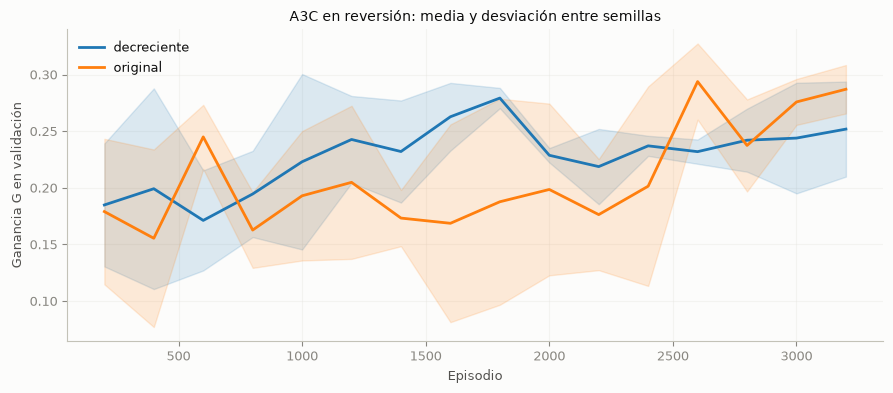

Menor oscilación solo mejora el resultado si se mantiene o aumenta el rendimiento.
Es una comparación exploratoria en validación, no un resultado final de test.


In [61]:
import inspect
from IPython.display import Code, display
from scripts.estabilidad_a3c import TrabajadorProgramado, comparar, mostrar_comparacion

# Cambio de aprendizaje respecto al trabajador original de A3C.
display(Code(inspect.getsource(TrabajadorProgramado), language="python"))

# Prueba r?pida. Para estudiar estabilidad a largo plazo: 12_800 episodios.
EPISODIOS_A3C = 3_200
SEMILLAS_A3C = (350, 351, 352)
EJECUTAR_MEJORA_A3C = True  # False: mostrar solo los resultados guardados.

curvas_mejora_a3c = comparar(
    episodios=EPISODIOS_A3C,
    semillas=SEMILLAS_A3C,
    evaluar_cada=200,
    trabajadores=4,
    n_validacion=100,
    ejecutar=EJECUTAR_MEJORA_A3C,
)
detalle_mejora_a3c = mostrar_comparacion(curvas_mejora_a3c)


### A3C: reducir solo el aprendizaje

**Por qué hacemos esta prueba.** En los ensayos anteriores de reversión a la media, reducir solo el aprendizaje dio un mejor equilibrio entre ganancia y oscilación que reducir también la entropía. Comparamos A3C original con una variante que reduce progresivamente las tasas del actor y del crítico hasta el **10 %** de su valor inicial durante el primer 80 % del entrenamiento. Después se mantienen constantes.

**El calendario original de entropía se conserva en ambas variantes** para aislar el efecto de la tasa de aprendizaje. Usamos 3.200 episodios, las mismas tres semillas y 100 series de validación. La tabla y la gráfica permiten comprobar si disminuyen la oscilación y la diferencia entre mejor y último control sin perder rendimiento. Es una prueba exploratoria: no utiliza test ni demuestra por sí sola estabilidad a largo plazo.


Resultados: C:\Users\Natalia\workplace\Taller_2_RL_Miax\results\estabilidad_a3c_reversion\e35db19ef62e
Entrenando original, semilla 350...
Completado en 1.2 min
Entrenando original, semilla 351...
Completado en 1.2 min
Entrenando original, semilla 352...
Completado en 1.7 min
Entrenando solo_aprendizaje, semilla 350...
Completado en 1.8 min
Entrenando solo_aprendizaje, semilla 351...
Completado en 2.1 min
Entrenando solo_aprendizaje, semilla 352...
Completado en 2.0 min


,semillas,G_final,oscilacion,deriva,rango_semillas,retorno_final_pct,brecha_mejor_ultimo_pp,segundos_entrenamiento
variante,,,,,,,,
original,3,0.2180,0.0388,0.0150,0.1251,8.8349,19.5789,74.3293
solo_aprendizaje,3,0.2076,0.0182,-0.0064,0.1320,15.2995,7.0147,110.2023


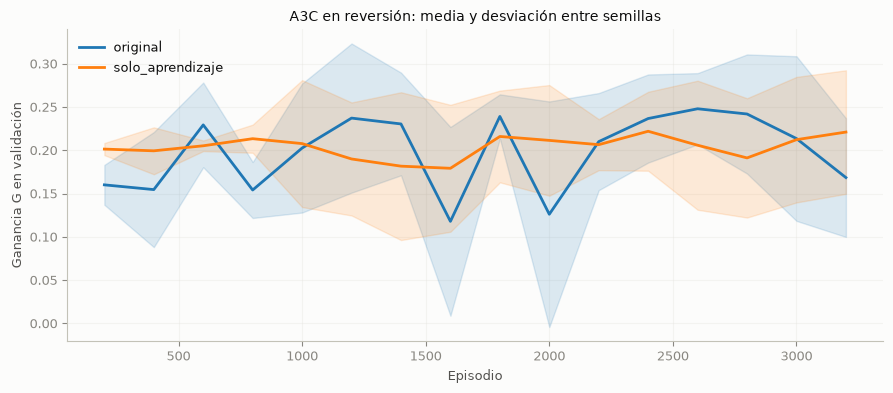

Menor oscilación solo mejora el resultado si se mantiene o aumenta el rendimiento.
Es una comparación exploratoria en validación, no un resultado final de test.


In [62]:
from importlib import reload
from scripts import estabilidad_a3c
reload(estabilidad_a3c)
curvas_solo_alpha = estabilidad_a3c.comparar(solo_aprendizaje=True)
detalle_solo_alpha = estabilidad_a3c.mostrar_comparacion(curvas_solo_alpha)


### Interpretación: reducir solo el aprendizaje

En esta prueba de **3.200 episodios y tres semillas (350, 351 y 352)**, reducir las tasas del actor y del crítico hasta el 10 % mejora la estabilidad, pero empeora el rendimiento. Ambas variantes mantienen el mismo calendario original de entropía.

| Métrica en validación | A3C original | Solo reducir aprendizaje |
|---|---:|---:|
| Ganancia G media del último cuarto | **0,2304** | 0,1997 |
| Oscilación del último cuarto | 0,0408 | **0,0195** |
| Rentabilidad del último control | **21,94 %** | 13,23 % |
| Diferencia entre mejor y último control | **6,66 puntos** | 9,47 puntos |

Las cifras son medias entre las tres semillas. La rentabilidad es la media de las medianas obtenidas en las series de validación; la oscilación es la desviación de G entre los controles del último cuarto del entrenamiento. La diferencia entre mejor y último control se calcula sobre la rentabilidad mediana, en puntos porcentuales.

**Qué significa.** La oscilación disminuye aproximadamente un **52 %**, pero la ganancia del tramo final cae un **13 %**. El agente se estabiliza en un nivel de rendimiento peor y el último control queda más lejos del mejor. Por tanto, **esta configuración no mejora globalmente al A3C original**.

**Posible explicación.** Reducir la tasa hasta el 10 % durante solo 3.200 episodios podría frenar el aprendizaje demasiado pronto. Es una hipótesis, no una causa demostrada. El resultado favorable observado con 12.800 episodios corresponde a otro presupuesto de entrenamiento y no se reproduce en esta prueba corta.

**Siguiente prueba propuesta (todavía no realizada aquí).** Reducir más suavemente, hasta el **30 %** de la tasa inicial, manteniendo la entropía y el resto de condiciones. Esto permitiría comprobar si se puede conservar la estabilidad sin perder tanto rendimiento.

> **Conclusión para el informe:** La reducción de la tasa de aprendizaje disminuyó la oscilación, pero también redujo el rendimiento en validación. Con 3.200 episodios, el calendario probado no mejoró globalmente al A3C original.

Estos resultados describen el experimento guardado en `results/estabilidad_a3c_reversion/0a15192dd759/`. Son exploratorios, con tres semillas y sin evaluación en un test nuevo. Si se repite el entrenamiento, hay que revisar las cifras y esta interpretación, porque A3C es asíncrono.


### 1. Probar una reducción menos brusca: 10 % frente a 30 %

La reducción al 10 % estabilizó la prueba corta, pero perdió rendimiento. Probamos si terminar al **30 %** permite seguir aprendiendo sin tanta oscilación. Comparamos **tasa constante, 10 % y 30 %**, con 3.200 episodios, las mismas semillas (350–352), 100 series de validación y el calendario original de entropía. Solo cambia la tasa de aprendizaje del actor y del crítico.

**Regla fijada antes de ver los resultados:** una alternativa debe tener ganancia G media del último cuarto y rentabilidad del último control no inferiores al original, y menor oscilación. Si pasan varias, se elige la de mayor G; si ninguna pasa, se conserva el original. Es un criterio exploratorio, no una prueba de significación estadística.

**Lectura de la salida:** la tabla muestra rendimiento, oscilación, brecha entre mejor y último control y tiempo de entrenamiento. El comentario final identifica el candidato real, sin asumir que el 30 % vaya a ganar. Los tiempos dependen de la carga del equipo.


Resultados: C:\Users\Natalia\workplace\Taller_2_RL_Miax\results\estabilidad_a3c_reversion\b524af4c8dbb
Entrenando original, semilla 350...
Completado en 1.4 min
Entrenando original, semilla 351...
Completado en 1.2 min
Entrenando original, semilla 352...
Completado en 1.2 min
Entrenando alpha_10, semilla 350...
Completado en 1.2 min
Entrenando alpha_10, semilla 351...
Completado en 1.2 min
Entrenando alpha_10, semilla 352...
Completado en 1.2 min
Entrenando alpha_30, semilla 350...
Completado en 1.2 min
Entrenando alpha_30, semilla 351...
Completado en 1.2 min
Entrenando alpha_30, semilla 352...
Completado en 1.2 min


,semillas,G_final,oscilacion,deriva,rango_semillas,retorno_final_pct,brecha_mejor_ultimo_pp,segundos_entrenamiento
variante,,,,,,,,
alpha_10,3,0.1955,0.0079,0.0176,0.1382,12.7193,4.5993,63.6804
alpha_30,3,0.2328,0.0374,0.0012,0.0676,16.5846,8.3330,63.6550
original,3,0.2378,0.0529,0.0062,0.0187,16.0949,13.1405,67.8355


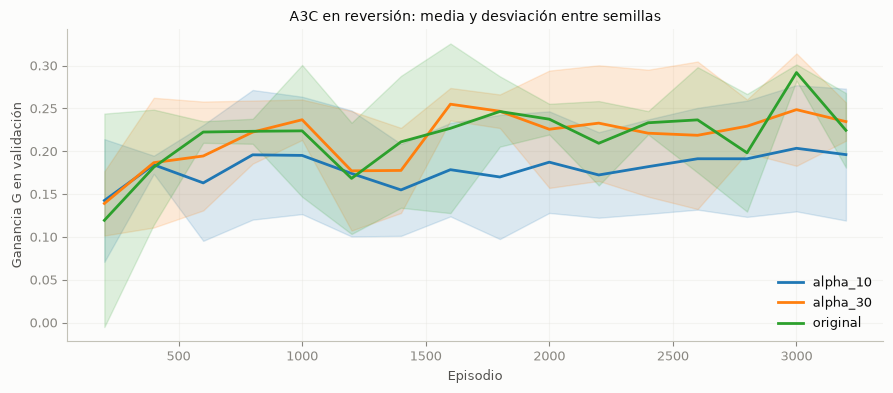

Menor oscilación solo mejora el resultado si se mantiene o aumenta el rendimiento.
Es una comparación exploratoria en validación, no un resultado final de test.
Candidato para confirmar: original.
Regla: G y rentabilidad final no inferiores al original, y menor oscilación.
Ninguna reducción cumple la regla: no hay mejora conjunta en esta búsqueda.


In [63]:
from importlib import reload
from scripts import estabilidad_a3c
reload(estabilidad_a3c)
# Solo validacion: comparar tres calendarios y elegir con la regla descrita arriba.
busqueda_alpha = estabilidad_a3c.explorar_aprendizaje(episodios=3_200)


### 2. Confirmar con semillas nuevas

Repetimos el candidato y A3C original con **cinco semillas nuevas (360–364)**. Conservamos el presupuesto, las series de validación, la entropía y el resto de parámetros del paso 1. No ampliamos la búsqueda ni probamos otra alternativa si esta falla.

Para confirmar, el candidato debe volver a cumplir la regla del paso 1 y alcanzar una G del tramo final no inferior al original en **al menos tres de las cinco semillas**. Si no lo consigue, se conserva el original. Si el paso 1 ya descartó todas las alternativas, solo se repite el original. Esto comprueba sensibilidad a la aleatoriedad del entrenamiento, no generalización a datos nuevos.

**Lectura de la salida:** se indican las semillas favorables y la decisión. Esta se guarda en un archivo **antes de abrir el test**. Las curvas de A3C pueden variar entre ejecuciones por su asincronía; los ensayos completos se reutilizan.


Resultados: C:\Users\Natalia\workplace\Taller_2_RL_Miax\results\estabilidad_a3c_reversion\1e9c1784f2f4
Entrenando original, semilla 360...
Completado en 1.2 min
Entrenando original, semilla 361...
Completado en 1.2 min
Entrenando original, semilla 362...
Completado en 1.2 min
Entrenando original, semilla 363...
Completado en 1.2 min
Entrenando original, semilla 364...
Completado en 1.2 min


,semillas,G_final,oscilacion,deriva,rango_semillas,retorno_final_pct,brecha_mejor_ultimo_pp,segundos_entrenamiento
variante,,,,,,,,
original,5,0.1888,0.0525,0.0037,0.1014,16.1271,11.8517,63.4383


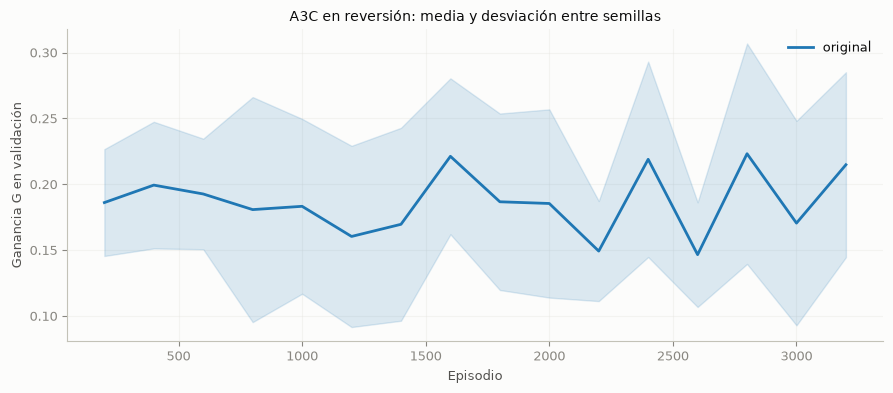

Menor oscilación solo mejora el resultado si se mantiene o aumenta el rendimiento.
Es una comparación exploratoria en validación, no un resultado final de test.
Decisión antes del test: original.
No se confirma una mejora conjunta: se conserva A3C original.


In [64]:
# Semillas nuevas; no volver a ajustar hiperparametros durante esta confirmacion.
decision_alpha = estabilidad_a3c.confirmar_aprendizaje(
    busqueda_alpha, semillas=(360, 361, 362, 363, 364)
)


### 3. Evaluar la decisión en un test nuevo reservado

Solo ahora se generan **100 series nuevas de reversión**, con semillas desde 4.170.000.000, separadas de entrenamiento, validación, normalización y test anterior. La configuración ya está fijada. Comparamos la alternativa confirmada con el original sobre las mismas series y las mismas semillas de entrenamiento; si ninguna alternativa se confirmó, evaluamos solo el original.

El **último control** es la comparación principal para estudiar la estabilidad. Se muestra también el **mejor control elegido en validación**, como diagnóstico secundario: no se eligen pesos con el test. La ganancia es la media por serie y semilla; la rentabilidad mostrada es la media entre semillas de las medianas por serie.

**Lectura de la salida:** se informa si ambas métricas mejoran, si el resultado es mixto o si solo se evalúa el original. Estos resultados son descriptivos, no una prueba de significación estadística. No se deben utilizar para volver a ajustar los parámetros. Al repetir esta celda se muestran los resultados guardados, no otro test nuevo.


In [65]:
# Evaluar la decision ya guardada; el resultado del test no cambia los parametros.
resultados_test_alpha = estabilidad_a3c.evaluar_test_reservado(decision_alpha)


ganancia_G  retorno_mediana_pct
variante control                                 
original mejor        0.2941              26.6684
         ultimo       0.2221              16.1743

Se evalúa el original: ninguna alternativa superó el criterio previo al test.
Resultados descriptivos: no prueban significación estadística. No reajustar con este test.


### Prueba rápida: una gráfica de ganancia en directo

Antes de los experimentos largos, un entrenamiento corto de cada algoritmo en el mercado de ciclo (unos 2 minutos), para ver cómo sube la ganancia $G = \sum r$ de cada episodio mientras aprende. Es solo una demostración: los resultados serios vienen después.

DQN, 150 episodios: 17 s
A3C con 4 trabajadores, 600 episodios: 18 s


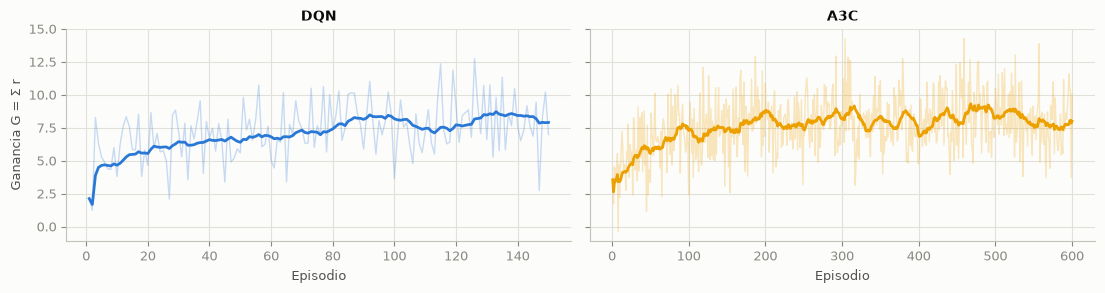

In [66]:
g = GENERADORES["ciclo"]
normalizador = Normalizador.ajustar(g)
validacion = np.array(generar_series(g, 50, SEMILLA_VALIDACION))

t0 = time.perf_counter()
demo_dqn = entrenar_dqn(g, normalizador, n_episodios=150, gamma=0.0, alpha=5e-4, seed=1, precios_validacion=validacion,
                        evaluar_cada=25)
print(f"DQN, 150 episodios: {time.perf_counter() - t0:.0f} s")
t0 = time.perf_counter()
demo_a3c = entrenar_a3c(g, normalizador, n_episodios=600, gamma=0.9, seed=1, n_trabajadores=4,
                        precios_validacion=validacion, evaluar_cada=50)
print(f"A3C con 4 trabajadores, 600 episodios: {time.perf_counter() - t0:.0f} s")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, res, nombre, color in ((ejes[0], demo_dqn, "DQN", "dqn"), (ejes[1], demo_a3c, "A3C", "a3c")):
    h = res.historial
    ax.plot(h["episodio"], h["ganancia"], color=graficas.COLORES[color], alpha=0.25, linewidth=1)
    ax.plot(h["episodio"], h["ganancia"].rolling(20, min_periods=1).mean(), color=graficas.COLORES[color])
    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Episodio")
ejes[0].set_ylabel("Ganancia G = Σ r")
fig.tight_layout()
plt.show()

## 3. Ajuste de hiperparámetros (ejercicio 3)

Probar todas las combinaciones sería demasiado lento, así que se ajusta por etapas. Cada una parte de lo mejor de la anterior, por mercado y solo con las series de **validación** (3 semillas × 100 series):

| Etapa | Qué ajusta | DQN | A3C |
|---|---|---|---|
| A | α × γ | α ∈ {0,0001; 0,0005; 0,002} × γ ∈ {0; 0,5; 0,9; 0,99} | α ∈ {0,0001; 0,0003; 0,001} × los mismos γ |
| B | Exploración | 3 calendarios de ε | β ∈ {0,01; 0,05; 0,2} × n ∈ {5, 20} |
| C | Pérdida | MSE o MAE (TD) | MSE o MAE (crítico) |
| D | Episodios | 400, 800, 1.600 | 800, 1.600, 3.200 |

REINFORCE hace una búsqueda más pequeña en las etapas A, B y D. Doble DQN y DQN en duelo usan la configuración de DQN, para medir solo el efecto de cada variante.

En la etapa D se elige el menor número de episodios que queda a menos de un 5% (o 1 punto) del mejor, porque entrenar más cuesta tiempo.

La siguiente celda lanza el ajuste, y su progreso va saliendo debajo. **No ejecutes el notebook dos veces a la vez:** dos procesos repetirían los mismos entrenamientos.

In [67]:
if EJECUTAR_CALCULOS:
    ajuste.main()

if hay("mejores.csv"):
    display(analisis.configuraciones_elegidas().drop(columns=["seed", "evaluar_cada"], errors="ignore").round(5))

[23:05:20] dqn/a: 0 de 144 entrenamientos
[23:05:20] dqn/b: 0 de 36 entrenamientos
[23:05:20] dqn/c: 0 de 24 entrenamientos
[23:05:20] dqn/d: 0 de 36 entrenamientos
[23:05:20] reinforce/a: 0 de 72 entrenamientos
[23:05:20] reinforce/b: 0 de 36 entrenamientos
[23:05:20] reinforce/d: 0 de 36 entrenamientos
[23:05:20] a3c/a: 0 de 144 entrenamientos
[23:05:20] a3c/b: 0 de 72 entrenamientos
[23:05:20] a3c/c: 0 de 24 entrenamientos
[23:05:20] a3c/d: 0 de 36 entrenamientos
[23:05:20] ajuste terminado


,familia,mercado,algoritmo,alpha,eps_final,eps_inicial,frac_decaimiento,gamma,n_episodios,perdida,beta_final,beta_inicial,alpha_critico,n_pasos,n_trabajadores,perdida_critico
0,dqn,ciclo,dqn,0.0020,0.01,1.0,0.7,0.00,400,mae,NaN,NaN,NaN,NaN,NaN,NaN
1,dqn,browniano,dqn,0.0005,0.01,1.0,0.7,0.99,400,mse,NaN,NaN,NaN,NaN,NaN,NaN
2,dqn,reversion,dqn,0.0020,0.01,1.0,0.7,0.50,400,mse,NaN,NaN,NaN,NaN,NaN,NaN
3,dqn,regimenes,dqn,0.0005,0.10,1.0,0.7,0.50,400,mse,NaN,NaN,NaN,NaN,NaN,NaN
4,reinforce,ciclo,reinforce,0.0010,NaN,NaN,0.7,0.50,800,NaN,0.001,0.01,NaN,NaN,NaN,NaN
5,reinforce,browniano,reinforce,0.0010,NaN,NaN,0.7,0.99,800,NaN,0.001,0.01,NaN,NaN,NaN,NaN
6,reinforce,reversion,reinforce,0.0010,NaN,NaN,0.7,0.90,1600,NaN,0.001,0.05,NaN,NaN,NaN,NaN
7,reinforce,regimenes,reinforce,0.0003,NaN,NaN,0.7,0.50,800,NaN,0.001,0.01,NaN,NaN,NaN,NaN
8,a3c,ciclo,a3c,0.0003,NaN,NaN,0.7,0.00,1600,NaN,0.001,0.01,0.0009,20.0,4.0,mae
9,a3c,browniano,a3c,0.0003,NaN,NaN,0.7,0.99,800,NaN,0.001,0.01,0.0009,20.0,4.0,mae


**Qué se eligió y por qué.**

- **γ = 0 en ciclo**, en DQN y A3C. La inercia del ciclo se ve ya en el paso siguiente, así que no hace falta mirar más lejos. Coincide con el taller tabular.
- **γ alto en reversión** (0,5 en DQN; 0,9 en A3C y REINFORCE). Hay que aguantar la posición hasta que el precio vuelve a la media, y eso son muchos pasos.
- **Browniano y regímenes:** casi todas las configuraciones acaban sin operar (0%), y las diferencias son del tamaño del ruido (sección 10). Ahí la elección es casi arbitraria.
- **A3C pide más episodios que DQN** (1.600 en ciclo y 3.200 en reversión, frente a 400). Pero cada episodio le cuesta 3 veces menos (0,04 s frente a 0,13 s): 4 trabajadores se reparten el trabajo y no hay buffer ni red objetivo.
- **MAE en el crítico de A3C** en los cuatro mercados. DQN se queda con MSE salvo en ciclo.

### Etapa A: efecto de α y γ

Cada casilla es la mediana del retorno en validación, promediada entre semillas. El color es relativo dentro de cada panel.

**DQN**

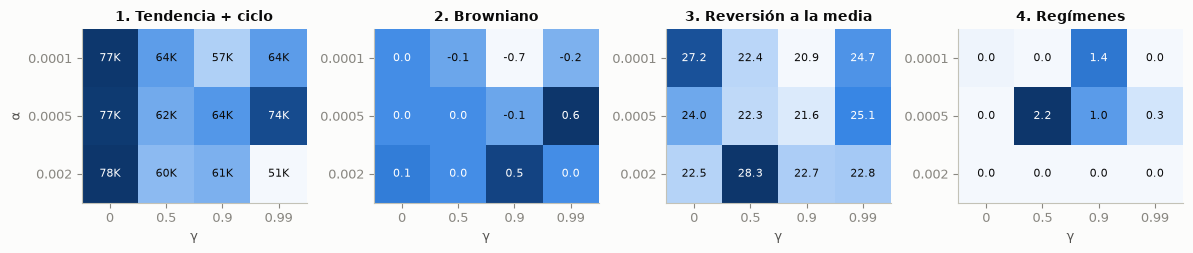

**A3C**

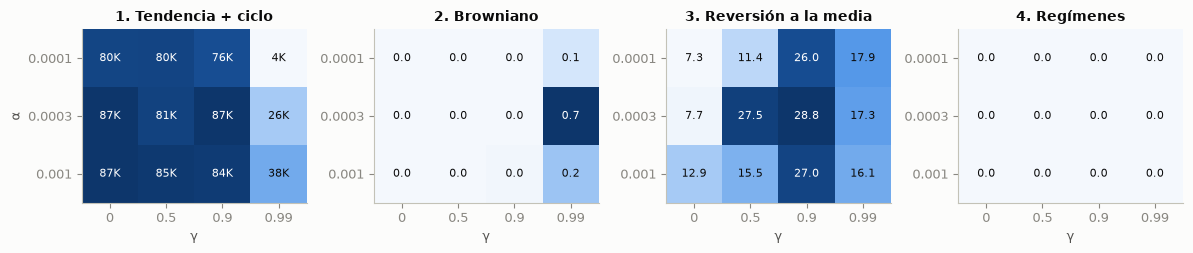

**REINFORCE**

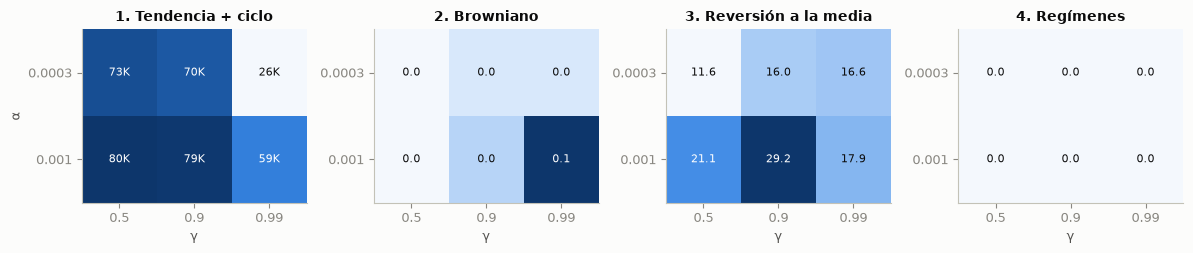

In [68]:
for familia, titulo in (("dqn", "DQN"), ("a3c", "A3C"), ("reinforce", "REINFORCE")):
    if hay(f"ajuste_{familia}_a.csv"):
        display(Markdown(f"**{titulo}**"))
        graficas.graficar_ajuste(familia, nombre=f"ajuste_{familia}")
        plt.show()

### Etapa C: MSE frente a MAE

La teoría da una predicción concreta. Con MSE, Q aproxima $\mathbb{E}[\text{target}]$, que es lo que pide la ecuación de Bellman. Con MAE aproxima la **mediana** del target: es más robusta al ruido de los precios, pero deja de estimar el valor esperado. Si el ruido del retorno es casi simétrico, media y mediana coinciden y ambas deberían rendir parecido. Donde hay asimetría o colas, pueden diferir.

,mercado,perdida,val_mediana,val_ganancia,val_operaciones,episodio_convergencia,familia
0,browniano,mae,0.00,0.00,0.00,133.33,dqn
1,browniano,mse,0.59,0.07,1.94,116.67,dqn
2,ciclo,mae,79153.62,8.31,45.66,333.33,dqn
3,ciclo,mse,77576.55,8.44,41.40,250.00,dqn
4,regimenes,mae,0.00,0.00,0.04,333.33,dqn
5,regimenes,mse,2.82,0.04,8.20,300.00,dqn
6,reversion,mae,26.61,0.26,24.94,400.00,dqn
7,reversion,mse,28.34,0.30,25.98,300.00,dqn
8,browniano,mae,0.20,0.03,0.33,50.00,a3c
9,browniano,mse,0.01,0.03,0.33,133.33,a3c


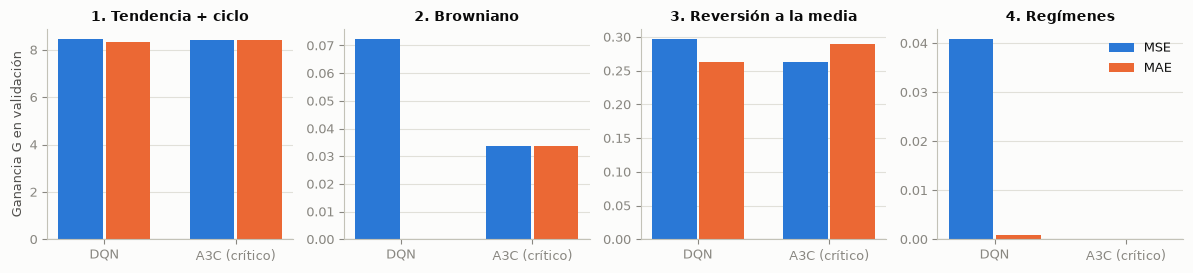

In [69]:
if hay("ajuste_dqn_c.csv", "ajuste_a3c_c.csv"):
    perdidas = analisis.tabla_perdidas()
    display(perdidas.round(2))
    graficas.graficar_perdidas(perdidas)
    plt.show()
elif hay("ajuste_dqn_c.csv"):
    d = pd.read_csv(RESULTADOS / "ajuste_dqn_c.csv")
    display(d.groupby(["mercado", "perdida"])[["val_mediana", "val_ganancia", "val_operaciones"]].mean().round(2))

**Resultado.** Ninguna diferencia supera con claridad el error de estimar con 3 semillas, que en reversión es de unos 2-3 puntos de mediana.

- **DQN:** MSE es algo mejor en reversión (+28,3% frente a +26,6%). Con MAE deja de operar en browniano y regímenes.
- **Crítico de A3C:** al revés, MAE es algo mejor en reversión (+26,6% frente a +23,8%). En ciclo empatan (G 8,42 y 8,41).

La teoría da una lectura coherente, aunque estos datos no la prueban:

- En DQN, la pérdida decide *qué* estima Q. La mediana del target ignora las colas de retorno, que son las que justifican entrar en un mercado con poca señal.
- En A3C, el crítico solo es la línea base que reduce la varianza del actor. Ahí sí ayuda que MAE sea robusta ante los retornos extremos.

## 4. Evaluación final (ejercicios 1 y 4)

Los agentes se entrenan de nuevo con **10 semillas nuevas** (100 a 109) y las configuraciones elegidas, y se prueban en las 100 series de test, que no se han usado para nada hasta aquí. Se evalúan también con el último control y, en los métodos de actor, con la política estocástica, como comprobación.

In [70]:
if EJECUTAR_CALCULOS and hay("mejores.csv"):
    resultados.main()
    comparar_lotes.main()
    datos_reales.main()

entrenamientos finales de dqn: ya calculados
entrenamientos finales de reinforce: ya calculados
entrenamientos finales de a3c: ya calculados
[23:05:22] resultados terminados
comparación de lotes: ya calculada
datos reales de dqn: ya calculados
datos reales de a3c: ya calculados


### Tabla comparativa

Rendimiento en test y convergencia, por mercado y agente. El tiempo de convergencia es el episodio de convergencia por los segundos por episodio medidos con la máquina descargada, porque durante los experimentos corren muchos entrenamientos a la vez.

El **criterio de convergencia** es el primer control a partir del cual la curva de validación, suavizada, ya no se aleja de su valor final más de un 10%. Se aplica a la mediana del retorno (`convergencia_ep`, con 2 puntos de tolerancia mínima) y a la ganancia $G$ (`convergencia_G_ep`, con 0,02).

mediana_pct  ganancia_G  sharpe  max_caida_pct  operaciones  dentro_pct  supera_BH_pct  mediana_min_semilla  mediana_max_semilla  episodios  convergencia_ep  \
mercado                 agente                                                                                                                                                                       
1. Tendencia + ciclo    Aleatorio          455.99        3.11    1.33          78.37       164.66       50.06           13.6                  NaN                  NaN        NaN              NaN   
                        Buy & hold        3425.12        6.38    1.94          88.57         1.00      100.00            0.0                  NaN                  NaN        NaN              NaN   
                        Momentum         48188.71        7.71    3.13          60.81        92.28       55.19           97.0                  NaN                  NaN        NaN              NaN   
                        Contrarian         -92.88       -1.52   -0.69          94.62        91.90       44.81            0.0                  NaN                  NaN        NaN              NaN   
                        DQN              59363.02        8.13    3.13          64.25        41.52       61.94           97.4             48024.43             69351.51      400.0            400.0   
                        Doble DQN        59363.02        8.13    3.13          64.25        41.52       61.94           97.4             48024.43             69351.51      400.0            400.0   
                        DQN en duelo     60722.89        8.18    3.10          65.20        42.19       63.81           97.6             50605.58             70544.31      400.0            400.0   
                        A3C              63618.96        8.21    3.15          64.07        34.06       62.31           97.2             57567.57             70113.58     1600.0           1425.0   
                        REINFORCE        59905.30        8.24    3.08          66.15        33.23       66.13           97.2             47732.28             70017.47      800.0            550.0   
2. Browniano            Aleatorio          -14.71       -0.11   -0.25          34.95       164.66       50.06           32.0                  NaN                  NaN        NaN              NaN   
                        Buy & hold           0.72        0.09    0.14          40.23         1.00      100.00            0.0                  NaN                  NaN        NaN              NaN   
                        Momentum           -11.84       -0.07   -0.17          33.39       118.58       49.96           35.0                  NaN                  NaN        NaN              NaN   
                        Contrarian         -14.32       -0.08   -0.18          33.77       118.48       50.04           35.0                  NaN                  NaN        NaN              NaN   
                        DQN                  0.00        0.03    0.05          16.10         1.19       39.77           38.4                -1.41                 1.97      400.0            150.0   
                        Doble DQN            0.00        0.06    0.08          27.45         3.40       63.53           35.9                -0.85                 0.52      400.0             50.0   
                        DQN en duelo         0.00        0.03    0.05          14.43         3.11       32.44           41.9                 0.00                 2.72      400.0            125.0   
                        A3C                  0.00        0.03    0.04          12.06         0.30       29.92           37.0                 0.00                 0.90      800.0             50.0   
                        REINFORCE            0.00        0.01    0.01           4.02         0.10       10.00           45.3                 0.00                 0.15      800.0             50.0   
3. Reversión a la media Aleatorio          -15.17       -0.12   -0.26         

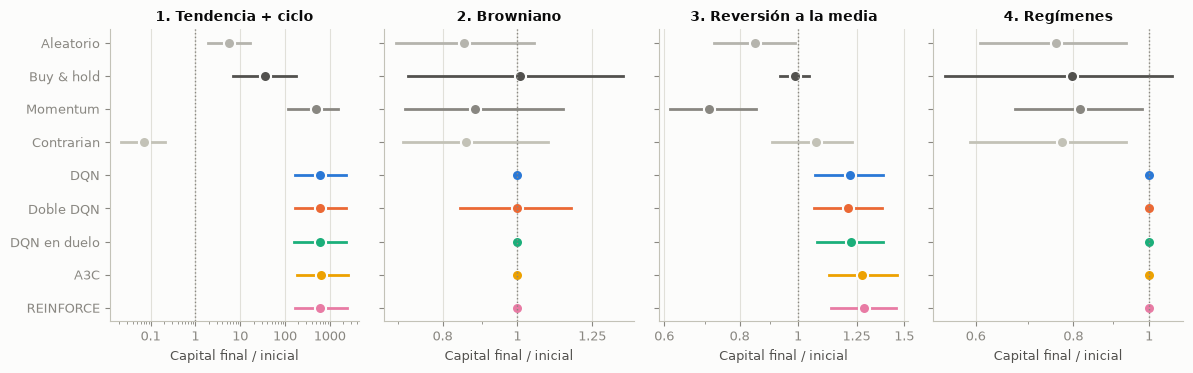

In [71]:
if hay("test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    test = analisis.cargar_test()
    tabla = analisis.tabla_resultados(test)
    tabla.to_csv(RESULTADOS / "tabla.csv", index=False)
    vista = tabla.assign(mercado=tabla.mercado.map(NOMBRES_MERCADO), agente=tabla.agente.map(NOMBRES_AGENTE))
    display(vista.set_index(["mercado", "agente"])[[
        "mediana_pct", "ganancia_G", "sharpe", "max_caida_pct", "operaciones", "dentro_pct", "supera_BH_pct",
        "mediana_min_semilla", "mediana_max_semilla", "episodios", "convergencia_ep", "convergencia_s",
        "convergencia_G_ep", "convergencia_G_s"]].round(2))
    graficas.graficar_capital(test)
    plt.show()

**Lectura de la tabla.**

- **Ciclo.** Todos los agentes multiplican el capital unas 600 veces en mediana, y superan de forma significativa a buy & hold y a momentum (siguiente tabla).
  - A3C tiene la mejor mediana (+63.619%) y el rango entre semillas más estrecho (+57.568% a +70.114%).
  - Aun así, en ganancia $G$ los cinco quedan entre 8,13 y 8,24: las diferencias entre ellos son pequeñas.
- **Browniano.** Mediana del 0% en todos: la mayoría de semillas no opera y alguna hace buy & hold. Ninguno se distingue de buy & hold, y es lo esperado, porque no hay nada que aprender.
- **Reversión.** Los métodos de actor superan a la familia DQN: A3C +27,5% y REINFORCE +28,6%, frente a +21-22%. A3C es además el más estable entre semillas: su peor semilla da +25,2%, frente a +11,3% en DQN.
- **Regímenes.** Todos acaban sin operar (0%). Superan a todas las referencias, que pierden entre un 18 y un 24%, pero solo porque quedarse fuera evita las caídas del régimen malo.
- **Doble DQN da exactamente lo mismo que DQN en ciclo.** Con γ = 0, el target es solo $r$ y no hay `max` que sobreestimar. Sirve de comprobación de la implementación.

**Convergencia.** El criterio sobre la mediana en % (`convergencia_ep`) engaña en ciclo: una mediana de +80.000% varía más de un 10% entre controles por puro ruido, y por eso marca la convergencia casi al final.

- **Ciclo:** sobre $G$ (`convergencia_G_ep`), todos los agentes han convergido ya en el primer o segundo control, en 50-75 episodios y 2-8 s.
- **Reversión:** ninguno se estabiliza dentro de su presupuesto: DQN converge en el episodio 375 de 400 y A3C en el 3.200 de 3.200.
- **Browniano y regímenes:** el valor apenas significa nada, porque la curva salta entre no operar y buy & hold, dos políticas casi equivalentes.

### Comparación con los agentes tabulares del taller anterior

Las series de test son las mismas, así que la comparación es directa, aunque solo de medianas: Q-learning y Sarsa se entrenaron con el estado en intervalos. Responde a la pregunta de qué aporta quitar la discretización.

In [72]:
if hay("test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    ref = pd.read_csv(RESULTADOS / "referencia_tabular_fase3.csv")
    ref = ref[ref.agente.isin(["qlearning", "sarsa"])].set_index(["mercado", "agente"])["mediana_%"].unstack()
    redes = tabla[tabla.agente.isin(analisis.AGENTES_RL)].set_index(["mercado", "agente"])["mediana_pct"].unstack()
    display(ref.join(redes).loc[MERCADOS].round(1))

agente,qlearning,sarsa,a3c,doble_dqn,dqn,duelo,reinforce
mercado,,,,,,,
ciclo,64988.5,67861.2,63619.0,59363.0,59363.0,60722.9,59905.3
browniano,0.0,0.0,0.0,0.0,0.0,0.0,0.0
reversion,22.0,22.2,27.5,21.0,22.1,22.2,28.5
regimenes,1.7,4.7,0.0,0.0,0.0,0.0,0.0


**Frente al tabular, en las mismas series de test:**

| Mercado | Redes | Tabular (Q-learning / Sarsa) |
|---|---|---|
| Ciclo | Algo por debajo: +59.363% a +63.619% | +64.989% / +67.861% |
| Reversión | Mejor con los métodos de actor (+27% a +29%); DQN empata (+21% a +22%) | +22,0% / +22,2% |
| Regímenes | Ninguna red conserva margen (0%) | +1,7% / +4,7% |

**Quitar la discretización no da más rendimiento**: con un estado de una sola variable continua, una tabla de 8 a 40 intervalos ya aproxima bien la frontera de decisión. Sin las cifras por serie del tabular no se puede saber si estas diferencias son significativas.

**La convergencia sí cambia, pero no en todos.** Para comparar hay que usar el criterio del taller anterior, sobre la mediana en %:

| | Episodios hasta converger (ciclo / reversión) | Coste por episodio |
|---|---|---|
| DQN | 400 / 375 | 131 ms |
| A3C | 1.425 / 3.200 | 41 ms |
| Tabular | 600-2.600 / 3.300-3.700 | unos 10 ms |

- **Reversión:** DQN converge con unas 10 veces menos episodios que el tabular, porque generaliza entre tendencias parecidas. Pero cada episodio le cuesta 13 veces más, y en segundos tarda algo más (49 s frente a 29-30 s). A3C necesita tantos episodios como el tabular.
- **Ciclo:** este criterio no distingue nada, porque la mediana en % es demasiado ruidosa. Sobre $G$, todas las redes convergen en 50-75 episodios.

### ¿Son significativas las diferencias?

Cociente geométrico medio del capital final entre cada agente y cada referencia, en las mismas series, con intervalo de confianza bootstrap del 95%. Si el intervalo no incluye el 1, la diferencia es significativa.

In [73]:
if hay("test_por_serie.csv.gz", "test_baselines.csv"):
    comparaciones = analisis.tabla_comparaciones(test)
    comparaciones.to_csv(RESULTADOS / "comparaciones.csv", index=False)
    display(comparaciones[comparaciones.referencia.isin(["buy_and_hold", "aleatorio"])].round(3))

,mercado,agente,referencia,cociente,ic_bajo,ic_alto,significativo
0,ciclo,dqn,buy_and_hold,16.704,12.188,22.769,True
1,ciclo,dqn,aleatorio,108.807,83.079,141.498,True
4,ciclo,doble_dqn,buy_and_hold,16.704,12.188,22.769,True
5,ciclo,doble_dqn,aleatorio,108.807,83.079,141.498,True
8,ciclo,duelo,buy_and_hold,16.563,12.150,22.446,True
9,ciclo,duelo,aleatorio,107.892,82.716,139.725,True
12,ciclo,a3c,buy_and_hold,17.846,12.896,24.412,True
13,ciclo,a3c,aleatorio,116.246,88.464,151.414,True
16,ciclo,reinforce,buy_and_hold,16.597,12.113,22.474,True
17,ciclo,reinforce,aleatorio,108.110,82.555,141.087,True


Todas las diferencias con buy & hold y con el agente aleatorio son significativas, salvo en browniano: allí ningún agente se distingue de buy & hold. En ciclo, los agentes superan también a momentum, la mejor regla fija, por un factor de 1,25 a 1,35.

## 5. Gráficas de ganancia por episodio

La **ganancia** es $G = \sum r$, la suma sin descontar de las recompensas de un episodio. Tiene escala comparable entre mercados, a diferencia del retorno en %.

- **La primera figura** muestra la ganancia en cada episodio de entrenamiento, mientras el agente aún explora. Por eso puede quedar por debajo de lo que el agente sabe hacer sin explorar.
- **La segunda** muestra la política sin explorar, siempre en las mismas series de validación: es la que indica si de verdad está aprendiendo.

Cada fila es un mercado, con el mismo eje y a ambos lados. Las líneas grises son buy & hold y el agente aleatorio. Cada familia tiene su propio eje x porque usa distinto número de episodios.

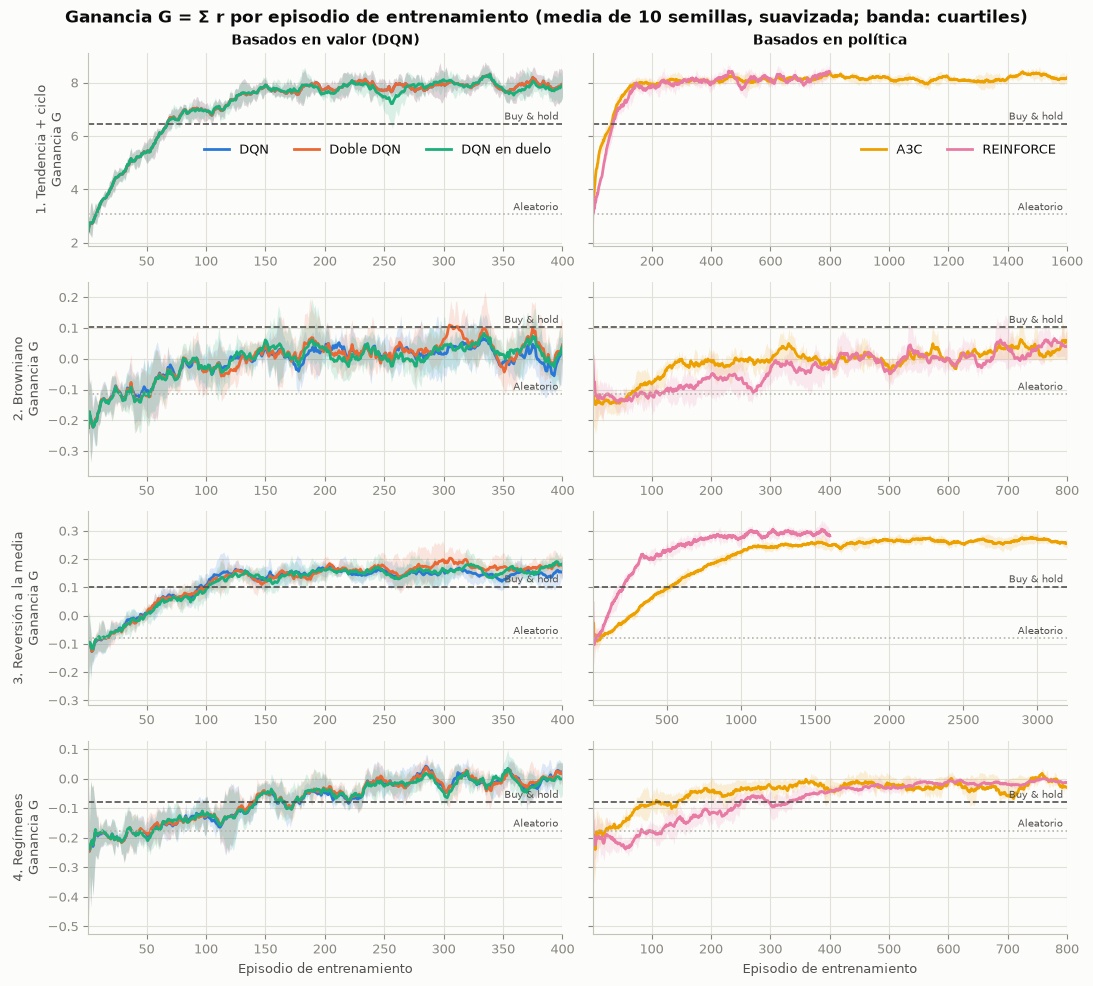

In [74]:
if hay("ganancia_episodios.csv.gz", "baselines_validacion.csv"):
    graficas.graficar_ganancia_episodios()
    plt.show()

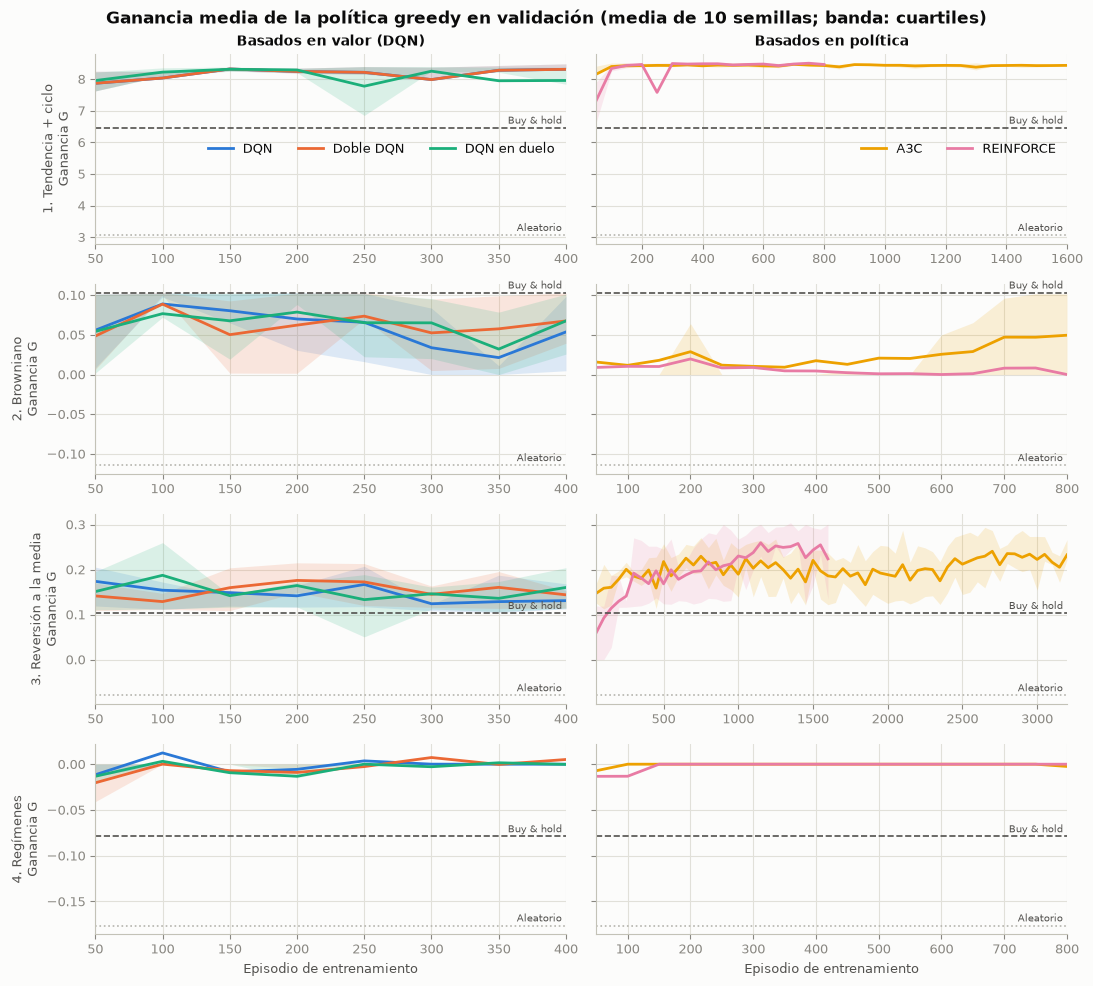

In [75]:
if hay("curvas_validacion.csv", "baselines_validacion.csv"):
    graficas.graficar_ganancia_validacion()
    plt.show()

**Qué muestran.**

- **Ciclo.** La ganancia de entrenamiento sube desde la del aleatorio (≈3) hasta ≈8. A DQN le cuesta unos 200 episodios y a A3C unos 150. La política greedy ya está en ≈8,3 en el primer control.
- **Reversión.** Cada familia tiene un ritmo distinto:
  - DQN llega pronto, hacia el episodio 120, a ≈0,15 de $G$ y ahí se queda.
  - REINFORCE sube a ≈0,28 en unos 800 episodios.
  - A3C, a ≈0,25 hacia el episodio 1.200.
  - Los métodos de actor son más lentos, pero llegan más alto.
- **Regímenes.** La ganancia de entrenamiento pasa de −0,2 a 0: lo que aprenden es a dejar de perder, no a ganar.

## 6. ¿Es la estrategia esperada? (ejercicio 2)

Como el estado es continuo, la política no es una tabla, sino una frontera de decisión. Cada panel muestra la fracción de las 10 semillas que quieren estar **dentro del mercado** según la tendencia, sin el activo (quiere comprar) y con él (no quiere vender). Si las dos filas difieren, el agente tiene histéresis: evita operar en la zona intermedia para ahorrar comisiones.

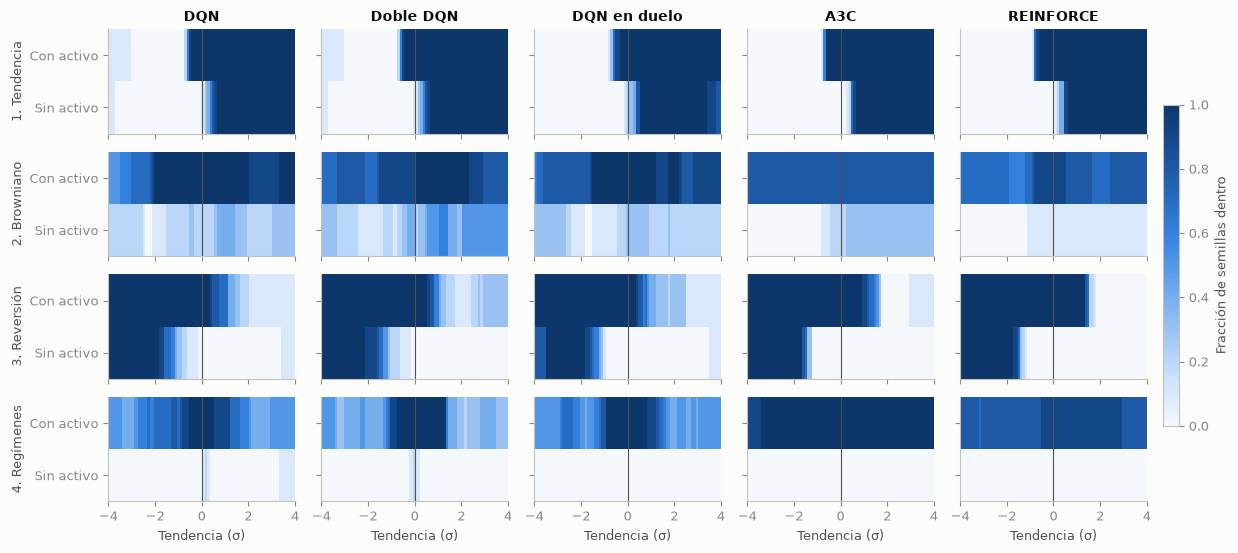

In [76]:
if hay("mapas_politica.npz"):
    graficas.graficar_politicas()
    plt.show()

**Sí es la estrategia esperada en los cuatro mercados:**

- **Ciclo: momentum con histéresis.** Sin activo, compran cuando la tendencia supera ≈ +0,5σ. Con activo, no venden hasta que baja de ≈ −0,7σ. La banda intermedia ahorra comisiones. Los cinco agentes coinciden.
- **Reversión: contrarian con histéresis.** Compran cuando la tendencia cae por debajo de ≈ −1,5σ y mantienen hasta que supera entre +1σ y +1,5σ. Solo operan en los extremos, donde el rebote compensa la comisión, tal como anticipaba la figura de la sección 1.
- **Browniano: indiferencia.** Sin activo rara vez compran; con activo, la mayoría mantiene. Como el episodio empieza sin activo, la mayoría de semillas no opera nunca, y las que compran al principio hacen buy & hold. Las dos respuestas son racionales en un mercado sin señal.
- **Regímenes: no operar.** Sin activo, ninguna semilla compra con ninguna tendencia: la tendencia de 6 pasos no distingue el régimen bueno del malo. Es lo que se esperaba ("poco margen sobre no operar"), llevado al extremo.

## 7. Minibatch frente a episodio entero

La base es el minibatch del buffer, como en las transparencias. Aquí se compara con que la red vea **el episodio entero de una vez** al terminar cada serie, con las mismas semillas e hiperparámetros, en dos intensidades:

- **1 pasada:** un paso de gradiente por episodio.
- **16 pasadas:** usa tantas experiencias como el minibatch (123 actualizaciones de 64 ≈ 16 pasadas de 494).

Sin buffer, la red no mezcla series distintas, y las experiencias de cada actualización están correlacionadas: es justo el problema que el buffer resuelve según las transparencias. Esta comparación no elige nada: la configuración final no cambia.

In [77]:
if hay("lotes_test.csv.gz", "test_por_serie.csv.gz"):
    lotes = pd.read_csv(RESULTADOS / "lotes_test.csv.gz")
    base = test[test.agente == "dqn"].assign(variante="Minibatch")
    lotes = lotes.assign(variante=lotes.pasadas.map({1: "Episodio, 1 pasada", 16: "Episodio, 16 pasadas"}))
    comparacion = pd.concat([base, lotes]).groupby(["mercado", "variante"]).agg(
        mediana_pct=("retorno_pct", "median"), ganancia_G=("ganancia", "mean"), operaciones=("operaciones", "mean"))
    display(comparacion.loc[MERCADOS].round(2))

mediana_pct  ganancia_G  operaciones
mercado   variante                                                  
ciclo     Episodio, 1 pasada       61586.22        8.19        38.59
          Episodio, 16 pasadas     61920.96        8.07        37.91
          Minibatch                59363.02        8.13        41.52
browniano Episodio, 1 pasada           0.00        0.04         1.82
          Episodio, 16 pasadas         0.00        0.01         0.10
          Minibatch                    0.00        0.03         1.19
reversion Episodio, 1 pasada          24.40        0.27        27.33
          Episodio, 16 pasadas        10.82        0.16        29.54
          Minibatch                   22.07        0.25        34.32
regimenes Episodio, 1 pasada           0.00        0.00         0.00
          Episodio, 16 pasadas         0.00        0.00         0.00
          Minibatch                    0.00        0.01         6.38

- **Una pasada por episodio iguala al minibatch** con muchas menos actualizaciones: en ciclo, $G$ = 8,19 frente a 8,13, y en reversión, +24,4% frente a +22,1%.
- **Dieciséis pasadas empeoran claramente en reversión:** +10,8%, con $G$ = 0,16. Repetir el gradiente sobre las mismas 494 experiencias correlacionadas ajusta la red a la última serie, que es justo lo que el buffer evita según las transparencias.
- **En ciclo no se nota,** porque la señal es tan fuerte que cualquier serie la enseña.

En este problema, el valor del buffer no está en aprender más de cada experiencia, sino en no olvidar las series anteriores.

## 8. Prueba con datos reales: índices y fondos

Prueba secundaria, como en el taller anterior, con dos índices y dos fondos descargados de Yahoo Finance:

| Activo | Tipo |
|---|---|
| S&P 500 | Índice, sin dividendos |
| IBEX 35 | Índice, sin dividendos |
| Vanguard Wellington | Fondo mixto, con dividendos |
| Vanguard Total Bond | Fondo de bonos, con dividendos |

De cada activo solo hay una historia, así que el protocolo cambia. Se entrena con **tramos de 500 días al azar hasta 2015**, para que cada episodio vea una serie distinta. Se eligen los pesos con **2016-2018** y se evalúa de una sola pasada desde **2019**. Los tramos solo reparten los episodios: el estado que ve la red sigue siendo continuo.

No se ajusta nada con datos reales, porque con una sola historia se sobreajustaría: se usa la configuración del mercado de regímenes.

Hay que leerlo con cautela: **cada activo tiene una única historia de test**, y 2019-2026 fue muy alcista para la renta variable. Además, los fondos de inversión suelen limitar las operaciones frecuentes, así que una estrategia muy activa no sería realista en ellos.

In [78]:
if hay("reales_resultados.csv"):
    reales = pd.read_csv(RESULTADOS / "reales_resultados.csv")
    resumen = reales.groupby(["activo", "agente", "periodo"])["retorno_pct"].median().unstack("periodo")
    display(resumen[["entrenamiento", "validacion", "test"]].round(1))
    display(Markdown("**Solo el periodo de test**, con riesgo y actividad. El mínimo y el máximo son entre semillas."))
    display(reales[reales.periodo == "test"].groupby(["activo", "agente"]).agg(
        mediana_pct=("retorno_pct", "median"), minimo_pct=("retorno_pct", "min"), maximo_pct=("retorno_pct", "max"),
        sharpe=("sharpe", "median"), max_caida_pct=("max_drawdown_pct", "median"),
        operaciones=("operaciones", "median"), dentro_pct=("tiempo_dentro_pct", "median")).round(1))

periodo              entrenamiento  validacion   test
activo agente                                        
bonos  a3c                     0.0         0.0    0.0
       aleatorio             -53.1       -17.8  -43.8
       buy_and_hold           57.2         5.3   12.2
       contrarian            -28.8       -13.6  -35.2
       dqn                     6.8         0.0    0.0
       momentum              -39.5       -14.3  -33.0
ibex   a3c                   -24.5         9.5  101.4
       aleatorio             -64.9       -21.7  -19.4
       buy_and_hold            6.3        -4.0  111.2
       contrarian            -24.6       -26.6  -22.8
       dqn                    27.8        11.0   35.1
       momentum              -61.8        -8.0    3.7
mixto  a3c                   116.4        27.7  105.8
       aleatorio             -40.8       -12.9  -23.5
       buy_and_hold          118.7        27.7  119.9
       contrarian              0.1        -7.3  -12.0
       dqn                   125.1        35.7   61.9
       momentum              -42.5        -2.2    2.8
sp500  a3c                    90.2        30.2  190.2
       aleatorio             -43.7       -12.5  -14.1
       buy_and_hold           71.6        30.2  192.9
       contrarian             92.6        -3.6   29.8
       dqn                   174.9        40.7  179.0
       momentum              -77.3        -8.2  -10.4

**Solo el periodo de test**, con riesgo y actividad. El mínimo y el máximo son entre semillas.

mediana_pct  minimo_pct  maximo_pct  sharpe  max_caida_pct  operaciones  dentro_pct
activo agente                                                                                           
bonos  a3c                   0.0        -0.2         4.0     0.0            0.0          0.0         0.0
       aleatorio           -43.8       -49.4       -37.8    -1.9           44.0        651.5        51.0
       buy_and_hold         12.2        12.2        12.2     0.3           18.8          1.0       100.0
       contrarian          -35.2       -35.2       -35.2    -1.4           35.4        478.0        46.7
       dqn                   0.0       -11.7        12.4     0.0            7.9          0.5        11.3
       momentum            -33.0       -33.0       -33.0    -1.3           37.0        477.0        53.2
ibex   a3c                 101.4         0.0       141.7     0.6           28.1          1.0        85.4
       aleatorio           -19.4       -48.9        52.5    -0.1           40.0        661.0        50.9
       buy_and_hold        111.2       111.2       111.2     0.6           39.4          1.0       100.0
       contrarian          -22.8       -22.8       -22.8    -0.1           41.6        485.0        42.3
       dqn                  35.1        -8.4       141.7     0.3           32.3         70.0        26.7
       momentum              3.7         3.7         3.7     0.1           28.9        486.0        57.7
mixto  a3c                 105.8         0.0       120.7     0.8           25.3          1.0        92.7
       aleatorio           -23.5       -39.9       -15.0    -0.4           31.9        651.5        51.0
       buy_and_hold        119.9       119.9       119.9     0.9           25.3          1.0       100.0
       contrarian          -12.0       -12.0       -12.0    -0.1           23.5        444.0        37.8
       dqn                  61.9        29.1       110.7     0.6           17.2        116.0        85.0
       momentum              2.8         2.8         2.8     0.1           21.0        445.0        62.2
sp500  a3c                 190.2       175.5       243.3     0.8           33.9          5.0        95.1
       aleatorio           -14.1       -40.9        -2.5    -0.1           34.1        651.5        51.0
       buy_and_hold        192.9       192.9       192.9     0.8           33.9          1.0       100.0
       contrarian           29.8        29.8        29.8     0.3           29.8        462.0        38.5
       dqn                 179.0        87.4       247.8     0.9           24.8         56.0        83.4
       momentum            -10.4       -10.4       -10.4    -0.1           30.6        463.0        61.5

**Ningún agente supera a buy & hold en test**, igual que en el taller anterior (allí, con otro periodo: S&P 500 +228% frente a +232%, e IBEX +9% frente a +117%).

- **A3C acaba haciendo buy & hold:** compra al principio, o tras unos días, y mantiene.
  - S&P 500: +190%, frente a +193% de buy & hold.
  - Fondo mixto: +106%, frente a +120%.
  - IBEX: +101%, frente a +111%.
  - En bonos no entra (0%, frente a +12%).
- **DQN opera más (56 a 116 operaciones) y cambia retorno por riesgo.** En el S&P 500 gana +179%, con una caída máxima del 25% frente al 34% de buy & hold (Sharpe 0,9 frente a 0,8). En el IBEX se queda en +35%.
- **Las reglas fijas pierden en casi todo:** el ruido diario les hace operar cientos de veces.

Con una sola historia de test por activo, y en un periodo muy alcista, no se puede generalizar. Lo único que se puede afirmar es que estos agentes no encuentran en los precios diarios una señal que compense salir del mercado.

## 9. Convergencia: ¿llega A3C a estabilizarse?

El criterio de la tabla dice cuándo se estabiliza una curva, pero no por qué no lo hace. Aquí se separan tres situaciones que requieren lecturas distintas:

| Medida | Si es grande, significa... |
|---|---|
| **Deriva:** cambio entre el penúltimo y el último cuarto de la curva | Aún no ha llegado: le falta experiencia |
| **Oscilación:** desviación dentro del último cuarto | Se acerca, pero no se asienta |
| **Caída desde el mejor control** | El mejor control fue un pico puntual, no un nivel que se mantiene |
| **Rango entre semillas** | El resultado depende de la suerte de la semilla |

Todas se miden sobre la ganancia $G$, con escala comparable entre mercados. Se calculan para todos los agentes, para poder comparar A3C con los demás.

### Un fallo que parecía falta de convergencia

La primera versión de A3C daba resultados inestables: con la misma configuración y semilla, unas veces aprendía y otras dejaba de operar para siempre. Parecía un rasgo del algoritmo, pero **era un fallo de la implementación**, y apareció porque un test falló de forma intermitente.

Los trabajadores comparten el estado de Adam ($m$ y $v$) y lo actualizaban sin cerrojo, igual que los pesos. Si un trabajador lee la $m$ que otro acaba de escribir y $v$ sigue a cero, el paso es $\alpha\, m / (\sqrt{v} + 10^{-8})$: **enorme**. Con $\alpha = 3 \cdot 10^{-4}$, los pesos deberían moverse unas centésimas en 8 episodios; en más de la mitad de las pruebas saltaban de 0,7 a más de 1.000. La política se satura en "no comprar", los gradientes se anulan y ya no se recupera. Con un cerrojo solo alrededor de ese paso, los pesos se quedan en 0,71 en 30 de 30 pruebas. DQN y REINFORCE no estaban afectados, porque tienen un solo hilo.

Se rehicieron el ajuste y la evaluación de A3C. La tabla compara el resultado **anterior al arreglo**, guardado para este análisis, con el actual.

In [79]:
if hay("a3c_sin_cerrojo.csv", "test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    antes = pd.read_csv(RESULTADOS / "a3c_sin_cerrojo.csv").set_index("mercado")
    ahora = tabla[tabla.agente == "a3c"].set_index("mercado")
    columnas = ["mediana_pct", "ganancia_G", "mediana_min_semilla", "mediana_max_semilla", "operaciones", "convergencia_ep"]
    display(pd.concat({"sin cerrojo": antes[columnas], "con cerrojo": ahora[columnas]}, axis=1).loc[MERCADOS].T.round(2))

mercado                             ciclo  browniano  reversion  regimenes
sin cerrojo mediana_pct          66087.77       0.00      23.57        0.0
            ganancia_G               8.17       0.03       0.27        0.0
            mediana_min_semilla  48968.29       0.00       5.29        0.0
            mediana_max_semilla  70913.16       1.44      30.24        0.0
            operaciones             34.56       0.40      37.00        0.0
            convergencia_ep        650.00      50.00    1600.00       50.0
con cerrojo mediana_pct          63618.96       0.00      27.45        0.0
            ganancia_G               8.21       0.03       0.30        0.0
            mediana_min_semilla  57567.57       0.00      25.15        0.0
            mediana_max_semilla  70113.58       0.90      29.80        0.0
            operaciones             34.06       0.30      22.63        0.0
            convergencia_ep       1425.00      50.00    3200.00       50.0

**Con el cerrojo, A3C deja de colapsar:**

- **Reversión:** la peor semilla pasa de +5,3% a +25,2%, y la mediana de +23,6% a +27,5%.
- **Ciclo:** la peor semilla pasa de +48.968% a +57.568%.
- **Ajuste:** los entrenamientos que no operaban bajan del 10% al 4% en reversión, y del 6% al 0% en ciclo.
- **Browniano y regímenes:** apenas cambian, porque ahí no operar es lo que se aprende, con o sin fallo.

In [80]:
if hay("curvas_validacion.csv"):
    display(analisis.diagnostico_convergencia(pd.read_csv(RESULTADOS / "curvas_validacion.csv")).round(3))

,mercado,agente,final,deriva,oscilacion,caida_desde_mejor,rango_semillas
0,browniano,a3c,0.043,0.023,0.010,0.018,0.103
1,browniano,doble_dqn,0.063,-0.000,0.012,0.038,0.103
2,browniano,dqn,0.037,-0.012,0.021,0.066,0.097
3,browniano,duelo,0.050,-0.015,0.028,0.053,0.101
4,browniano,reinforce,0.004,0.003,0.004,0.019,0.053
5,ciclo,a3c,8.424,-0.008,0.070,0.109,0.082
6,ciclo,doble_dqn,8.294,0.195,0.149,0.172,0.584
7,ciclo,dqn,8.294,0.195,0.149,0.172,0.584
8,ciclo,duelo,7.952,-0.061,0.224,0.483,2.101
9,ciclo,reinforce,8.467,-0.001,0.048,0.073,0.089


- **Ciclo:** A3C es de los más estables, con una oscilación de 0,07 y un rango entre semillas de 0,08. DQN tiene 0,15 y 0,58.
- **Reversión:** A3C es el único con una deriva clara (+0,034). Al final de sus 3.200 episodios todavía sube.

**Mejor control frente a último control, en test.** Si la política fuera estable, ambos pesos darían casi lo mismo. Una diferencia grande significa que la política oscila y que el resultado depende de cuándo se detiene el entrenamiento.

In [81]:
if hay("test_por_serie.csv.gz"):
    display(analisis.mejor_frente_a_ultimo().round(1))

version                 test  test_ultimo
mercado   agente                         
browniano a3c            0.0          0.0
          doble_dqn      0.0          0.0
          dqn            0.0          0.0
          duelo          0.0          0.0
          reinforce      0.0          0.0
ciclo     a3c        63619.0      55367.6
          doble_dqn  59363.0      44462.2
          dqn        59363.0      44462.2
          duelo      60722.9      35664.5
          reinforce  59905.3      51327.4
regimenes a3c            0.0          0.0
          doble_dqn      0.0          0.0
          dqn            0.0          0.0
          duelo          0.0          0.0
          reinforce      0.0          0.0
reversion a3c           27.5         15.9
          doble_dqn     21.0          3.0
          dqn           22.1          2.6
          duelo         22.2          5.7
          reinforce     28.5         11.2

**En reversión no se asienta ninguna familia.** Con los pesos del último control:

- DQN cae de +22,1% a +2,6%.
- A3C cae de +27,5% a +15,9%.

La oscilación no es exclusiva de A3C: A3C y REINFORCE pierden incluso menos que DQN. En este mercado, elegir el mejor control en validación es imprescindible.

**Entropía de la política final** de los métodos de actor, en proporción a la máxima. Cerca de 1, la política sigue siendo casi aleatoria aunque la versión greedy parezca razonable. Cerca de 0, ya es casi determinista.

In [82]:
if hay("mapas_politica.npz"):
    display(analisis.entropia_final().round(3))

agente,a3c,reinforce
mercado,,
browniano,0.800,0.938
ciclo,0.213,0.284
regimenes,0.878,0.968
reversion,0.386,0.353


- **Ciclo y reversión:** la política de A3C es bastante determinista (0,21 y 0,39). Ya ha decidido qué hacer.
- **Browniano y regímenes:** sigue cerca de la uniforme (0,80 y 0,88). Como no hay ventaja que aprender, el gradiente apenas la mueve, y la acción greedy depende de diferencias mínimas. Esto explica que, en esos mercados, la política greedy salte entre no operar y buy & hold.

**Escalado con el número de trabajadores.** Mismo entrenamiento de 800 episodios con 1, 2, 4 y 8 trabajadores: si la asincronía funciona, el tiempo debe bajar sin perder resultado.

In [83]:
if hay("escalado_a3c.csv"):
    display(pd.read_csv(RESULTADOS / "escalado_a3c.csv").groupby(["mercado", "trabajadores"]).agg(
        segundos=("segundos", "mean"), mediana_peor=("val_mediana", "min"), mediana_mejor=("val_mediana", "max"),
        convergencia_ep=("episodio_convergencia", "mean")).round(1))

segundos  mediana_peor  mediana_mejor  convergencia_ep
mercado   trabajadores                                                        
ciclo     1                 56.4       82360.6        85168.0            650.0
          2                 33.0       77579.5        81690.8            625.0
          4                 23.4       81190.9        82527.7            675.0
          8                 21.3       79240.7        82227.6            625.0
reversion 1                 57.8          23.9           26.3            625.0
          2                 34.3          22.3           23.5            750.0
          4                 24.3          20.2           27.2            525.0
          8                 21.8          26.4           28.5            675.0

**Con el cerrojo, el resultado no depende del número de trabajadores.** En ciclo, la mediana queda entre +77.580% y +85.168% con 1 a 8 trabajadores; en reversión, entre +20% y +28%.

| Trabajadores | 1 | 2 | 4 | 8 |
|---|---|---|---|---|
| Segundos | 57 | 33 | 23 | 21 |

A partir de 4 trabajadores apenas mejora. El cerrojo tiene un coste: sin él, 8 trabajadores tardaban 13-16 s, aunque con resultados que no servían.

**Entrenamiento largo.** A3C con 12.800 episodios, cuatro veces el máximo del ajuste, con los hiperparámetros elegidos y 3 semillas. Distingue si le faltaba experiencia (la curva sigue subiendo) o si oscila aunque tenga mucha más (la curva se mueve sin tendencia). No elige nada: la configuración final no cambia. Tarda alrededor de media hora.

convergencia de A3C: ya calculada


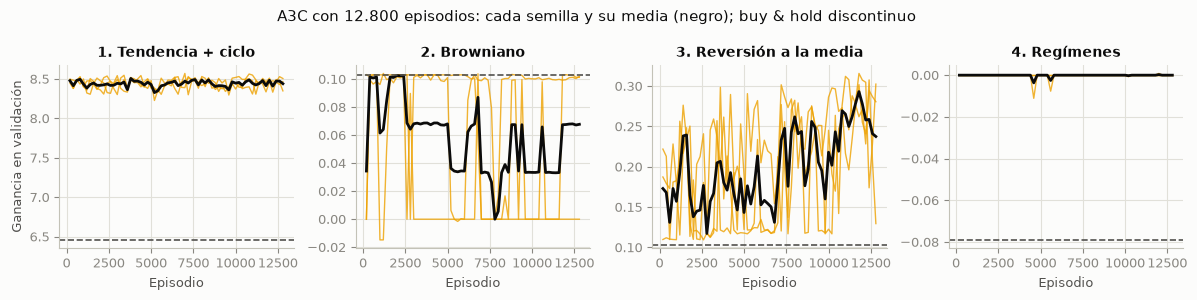

,mercado,agente,final,deriva,oscilacion,caida_desde_mejor,rango_semillas
0,browniano,a3c,0.048,0.007,0.017,0.055,0.100
1,ciclo,a3c,8.452,0.012,0.058,0.101,0.042
2,regimenes,a3c,0.000,0.000,0.000,0.000,0.000
3,reversion,a3c,0.246,0.034,0.056,0.063,0.010


In [84]:
if EJECUTAR_CALCULOS and hay("mejores.csv"):
    convergencia_a3c.main()

if hay("convergencia_a3c.csv", "baselines_validacion.csv"):
    largo = pd.read_csv(RESULTADOS / "convergencia_a3c.csv")
    referencias = pd.read_csv(RESULTADOS / "baselines_validacion.csv")
    fig, ejes = plt.subplots(1, 4, figsize=(12, 3))
    for ax, mercado in zip(ejes, MERCADOS):
        for seed, d in largo[largo.mercado == mercado].groupby("seed"):
            ax.plot(d["episodio"], d["ganancia"], color=graficas.COLORES["a3c"], linewidth=1, alpha=0.8)
        media = largo[largo.mercado == mercado].groupby("episodio")["ganancia"].mean()
        ax.plot(media.index, media.to_numpy(), color=graficas.TINTA, linewidth=2)
        fila = referencias[referencias.mercado == mercado].set_index("agente")["ganancia"]
        ax.axhline(fila["buy_and_hold"], color=graficas.GRISES["buy_and_hold"], linestyle="--", linewidth=1.2)
        ax.set_title(NOMBRES_MERCADO[mercado], fontweight="bold")
        ax.set_xlabel("Episodio")
    ejes[0].set_ylabel("Ganancia en validación")
    fig.suptitle("A3C con 12.800 episodios: cada semilla y su media (negro); buy & hold discontinuo", fontsize=11)
    fig.tight_layout()
    fig.savefig(graficas.FIGURAS / "convergencia_a3c.png", bbox_inches="tight")
    plt.show()
    display(analisis.diagnostico_convergencia(largo).round(3))

**Veredicto sobre la convergencia de A3C**, mercado por mercado:

- **Ciclo: converge pronto y se mantiene.** La ganancia queda entre 8,3 y 8,5 durante los 12.800 episodios, sin deriva (0,01) y con las tres semillas juntas (rango 0,04).
- **Browniano: no converge a una política, pero da igual.** Cada semilla salta entre buy & hold ($G$ ≈ 0,10) y no operar (0), que valen casi lo mismo.
- **Reversión: no converge.** Con 4 veces más episodios, cada semilla sigue alternando entre ≈0,12 y ≈0,30 de $G$. La media sube algo (deriva de 0,03), pero la oscilación (0,06) no baja. Es probable que se deba a que el paso de Adam no decrece y β no llega a cero, pero no lo hemos comprobado. Por eso pesa tanto elegir el mejor control.
- **Regímenes: converge a no operar** desde el principio.

**La impresión de que A3C no convergía tenía, por tanto, dos causas:**

1. El fallo del Adam compartido, ya corregido.
2. Una oscilación real en reversión, que DQN también tiene.

## 10. ¿Tienen sentido los resultados?

Tres comprobaciones independientes del entrenamiento.

**Techo teórico.** Un oráculo conoce la información oculta que ningún agente ve: la fase del ciclo, el nivel de precio o el régimen. Los agentes deben quedar por debajo de él y, si hay señal, por encima de las reglas fijas. En browniano, el oráculo solo es el mejor en esperanza, así que la comparación válida es la ganancia $G$, no la mediana.

In [85]:
if hay("test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    techos = tabla_oraculos(100, SEMILLA_TEST).set_index("mercado")
    agentes = tabla.set_index(["mercado", "agente"])
    filas = []
    for mercado in MERCADOS:
        for agente in ["a3c", "dqn", "doble_dqn", "duelo", "reinforce", "buy_and_hold", "momentum", "contrarian"]:
            fila = agentes.loc[(mercado, agente)]
            filas.append({"mercado": NOMBRES_MERCADO[mercado], "agente": NOMBRES_AGENTE[agente],
                          "mediana_pct": fila["mediana_pct"], "G": fila["ganancia_G"],
                          "G / G del oráculo": fila["ganancia_G"] / techos.loc[mercado, "ganancia_G"]})
    display(techos.round(2))
    display(pd.DataFrame(filas).set_index(["mercado", "agente"]).round(2))

,mediana_pct,ganancia_G,operaciones
mercado,,,
ciclo,1193433.00,11.16,17.00
browniano,0.72,0.09,1.00
reversion,77.33,0.62,51.45
regimenes,26.24,0.26,10.60


mediana_pct     G  G / G del oráculo
mercado                 agente                                            
1. Tendencia + ciclo    A3C              63618.96  8.21               0.74
                        DQN              59363.02  8.13               0.73
                        Doble DQN        59363.02  8.13               0.73
                        DQN en duelo     60722.89  8.18               0.73
                        REINFORCE        59905.30  8.24               0.74
                        Buy & hold        3425.12  6.38               0.57
                        Momentum         48188.71  7.71               0.69
                        Contrarian         -92.88 -1.52              -0.14
2. Browniano            A3C                  0.00  0.03               0.29
                        DQN                  0.00  0.03               0.38
                        Doble DQN            0.00  0.06               0.64
                        DQN en duelo         0.00  0.03               0.30
                        REINFORCE            0.00  0.01               0.10
                        Buy & hold           0.72  0.09               1.00
                        Momentum           -11.84 -0.07              -0.77
                        Contrarian         -14.32 -0.08              -0.96
3. Reversión a la media A3C                 27.45  0.30               0.48
                        DQN                 22.07  0.25               0.40
                        Doble DQN           20.96  0.24               0.39
                        DQN en duelo        22.20  0.25               0.39
                        REINFORCE           28.55  0.30               0.48
                        Buy & hold          -1.13  0.08               0.13
                        Momentum           -28.71 -0.28              -0.45
                        Contrarian           6.91  0.12               0.18
4. Regímenes            A3C                  0.00  0.00               0.00
                        DQN                  0.00  0.01               0.05
                        Doble DQN            0.00  0.01               0.04
                        DQN en duelo         0.00  0.00               0.00
                        REINFORCE            0.00  0.00               0.00
                        Buy & hold         -20.42 -0.17              -0.66
                        Momentum           -18.43 -0.16              -0.62
                        Contrarian         -22.63 -0.25              -0.95

**Comparación con el oráculo**, en proporción a su ganancia:

| Mercado | Agentes | Mejor regla fija |
|---|---|---|
| Ciclo | 74% | Momentum: 69% |
| Reversión | 48% con A3C y REINFORCE; 40% con DQN | Contrarian: 18% |

Siempre quedan por debajo del techo y por encima de la mejor regla fija. El hueco se explica por lo que el estado no ve: la fase del ciclo y la distancia a la media.

En regímenes, el oráculo gana +26% porque conoce el régimen, y los agentes se quedan en el 0%: con la tendencia de 6 pasos no hay forma de saber en qué régimen se está.

**Cuánto es ruido.** Compara lo que varía la nota entre configuraciones con el error de estimarla con 3 semillas. Si son parecidos, elegir la "mejor" configuración es en buena parte azar, y su ventaja en validación no se mantendrá en test.

In [86]:
filas = []
for familia in ("dqn", "reinforce", "a3c"):
    if not (RESULTADOS / f"ajuste_{familia}_a.csv").exists():
        continue
    a = pd.read_csv(RESULTADOS / f"ajuste_{familia}_a.csv")
    for mercado, d in a.groupby("mercado"):
        por_config = d.groupby(["alpha", "gamma"])["val_mediana"]
        filas.append({"familia": familia, "mercado": mercado, "entre_configuraciones": por_config.mean().std(),
                      "error_3_semillas": por_config.std().mean() / np.sqrt(3)})
display(pd.DataFrame(filas).round(2))

,familia,mercado,entre_configuraciones,error_3_semillas
0,dqn,browniano,0.33,0.23
1,dqn,ciclo,8725.93,4386.78
2,dqn,regimenes,0.72,0.41
3,dqn,reversion,2.26,2.05
4,reinforce,browniano,0.03,0.01
5,reinforce,ciclo,20275.50,6889.15
6,reinforce,regimenes,0.00,0.00
7,reinforce,reversion,5.97,5.45
8,a3c,browniano,0.20,0.06
9,a3c,ciclo,28445.61,5715.52


- **DQN:** la variación entre configuraciones apenas supera el error de 3 semillas (en reversión, 2,3 puntos frente a 2,1). Su elección en ese mercado es casi azar.
- **A3C:** las configuraciones sí se distinguen (en reversión, 7,7 frente a 2,9; en ciclo, 28.446 frente a 5.716). A3C es bastante más sensible a sus hiperparámetros.

**Optimismo del ajuste.** Compara la nota en validación de la configuración elegida con su resultado en test, en las mismas unidades de ganancia. Parte de la caída viene de que se eligió la mejor de muchas configuraciones y su mejor control.

In [87]:
if hay("test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    resumen_val = pd.read_csv(RESULTADOS / "entrenamientos.csv").groupby(["mercado", "agente"])["val_ganancia"].mean()
    display(pd.DataFrame({"G validación": resumen_val,
                          "G test": tabla.set_index(["mercado", "agente"])["ganancia_G"]}).dropna().round(3))

G validación  G test
mercado   agente                         
browniano a3c               0.030   0.025
          doble_dqn         0.065   0.056
          dqn               0.041   0.033
          duelo             0.030   0.026
          reinforce         0.010   0.009
ciclo     a3c               8.389   8.211
          doble_dqn         8.334   8.135
          dqn               8.334   8.135
          duelo             8.350   8.178
          reinforce         8.475   8.241
regimenes a3c               0.000   0.000
          doble_dqn         0.015   0.010
          dqn               0.013   0.014
          duelo             0.000   0.000
          reinforce         0.000   0.000
reversion a3c               0.300   0.303
          doble_dqn         0.235   0.242
          dqn               0.239   0.248
          duelo             0.247   0.245
          reinforce         0.302   0.303

**La ganancia en validación y en test es casi la misma.** En A3C: ciclo 8,39 frente a 8,21; reversión 0,30 frente a 0,30.

La pequeña caída en ciclo viene de que sus series de validación son más favorables: momentum da +57.715% en validación y +48.189% en test. Elegir el mejor control apenas infla el resultado.

## 11. Conclusiones

1. **Estrategia.** DQN y A3C aprenden lo esperado en cada mercado:
   - ciclo: momentum con histéresis;
   - reversión: contrarian solo en los extremos;
   - browniano: no operar o buy & hold, que son equivalentes;
   - regímenes: no operar.
2. **Rendimiento.**
   - **Ciclo:** todos empatan en $G$ (8,1-8,2, el 74% del oráculo) y superan a momentum.
   - **Reversión:** ganan los métodos de actor, con +27-29%, frente a +21-22% de la familia DQN.
   - **Browniano y regímenes:** no hay nada que ganar, y los agentes tampoco pierden.
   - **Variantes de DQN:** Doble DQN y DQN en duelo no cambian nada apreciable.
3. **Convergencia.**
   - **Ciclo:** todos convergen en menos de 10 s.
   - **Reversión:**
     - DQN converge en pocos episodios.
     - A3C necesita muchos más, aunque cada uno le cuesta 3 veces menos.
     - Ninguno se estabiliza del todo, y el mejor control en validación es imprescindible.
4. **Frente al tabular.** Mismo rendimiento en ciclo y algo mejor en reversión con los métodos de actor, pero se pierde el pequeño margen de regímenes. Con el mismo criterio, DQN converge en reversión con unas 10 veces menos episodios, porque generaliza, aunque cada uno le cuesta 13 veces más. A3C necesita tantos episodios como el tabular.
5. **MSE frente a MAE.** Sin diferencias claras: MSE es algo mejor en la Q de DQN, y MAE en el crítico de A3C.
6. **Lección de método.** Lo que parecía falta de convergencia de A3C era en buena parte un fallo de concurrencia, y lo destapó un test que fallaba de vez en cuando.
7. **Datos reales.** Ningún agente supera a buy & hold: A3C acaba haciendo buy & hold y DQN cambia retorno por menos riesgo.